# **Physicochemical analyses**

In [ ]:
import pandas as pd
import re

# Load the 4 files
files = {
    "AA1_708":     "Burgmaier_Genotype_Phenotype_Replication - AA1-708.csv",
    "AA709_1837":  "Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv",
    "AA1838_2624": "Burgmaier_Genotype_Phenotype_Replication - AA1838-2624.csv",
    "AA2625_4074": "Burgmaier_Genotype_Phenotype_Replication - AA2625-4074.csv",
}

def is_missense(variant):
    v = variant.strip()
    if not v.startswith('p.'):
        return False
    if any(x in v for x in ['*', 'fs', 'del', 'dup', 'ins', '?', 'ext', 'Ter']):
        return False
    return bool(re.match(r'p\.[A-Z][a-z]{2}\d+[A-Z][a-z]{2}$', v))

missense_variants = {}

for region, fname in files.items():
    df = pd.read_csv(fname)
    variants = []
    for entry in df['Predicted protein change'].dropna():
        for v in entry.split(';'):
            if is_missense(v.strip()):
                variants.append(v.strip())
    missense_variants[region] = sorted(set(variants))

# Unpack into named variables for downstream analyses
missense_AA1_708    = missense_variants["AA1_708"]
missense_AA709_1837 = missense_variants["AA709_1837"]
missense_AA1838_2624 = missense_variants["AA1838_2624"]
missense_AA2625_4074 = missense_variants["AA2625_4074"]

# Quick summary
for region, vlist in missense_variants.items():
    print(f"{region}: {len(vlist)} unique missense variants")

AA1_708: 19 unique missense variants
AA709_1837: 26 unique missense variants
AA1838_2624: 12 unique missense variants
AA2625_4074: 19 unique missense variants


In [ ]:
# Confirmation: tag each variant in the original data as missense or truncation

dfs = {}

for region, fname in files.items():
    df = pd.read_csv(fname)

    def classify_variants(entry):
        if pd.isna(entry):
            return "", ""
        variants = [v.strip() for v in entry.split(';')]
        missense = [v for v in variants if is_missense(v)]
        truncations = [v for v in variants if not is_missense(v)]
        return '; '.join(missense), '; '.join(truncations)

    df[['missense_extracted', 'truncation_extracted']] = df['Predicted protein change'].apply(
        lambda x: pd.Series(classify_variants(x))
    )

    dfs[region] = df

# Spot check — show rows where something was extracted as missense
for region, df in dfs.items():
    print(f"\n=== {region} ===")
    check = df[df['missense_extracted'] != ''][
        ['Predicted protein change', 'Functional class', 'missense_extracted', 'truncation_extracted']
    ]
    print(check.to_string(index=False))


=== AA1_708 ===
             Predicted protein change   Functional class       missense_extracted     truncation_extracted
              p.Ile222Val; p.Arg2955*     Null/ Mis1-708              p.Ile222Val               p.Arg2955*
                      p.Thr36Met; p.?     Null/ Mis1-708               p.Thr36Met                      p.?
              p.Thr36Met; p.Ile222Leu Mis1-708/ Mis1-708  p.Thr36Met; p.Ile222Leu                         
              p.Thr36Met; p.Ile222Val Mis1-708/ Mis1-708  p.Thr36Met; p.Ile222Val                         
         p.Leu115Serfs*8; p.Ile222Val     Null/ Mis1-708              p.Ile222Val          p.Leu115Serfs*8
               p.Thr36Met; p.Thr36Met Mis1-708/ Mis1-708   p.Thr36Met; p.Thr36Met                         
              p.Thr36Met; p.Tyr110His Mis1-708/ Mis1-708  p.Thr36Met; p.Tyr110His                         
               p.Thr36Met; p.Thr36Met Mis1-708/ Mis1-708   p.Thr36Met; p.Thr36Met                         
              p.Thr3

# **Non-significant biochemical effects**

            delta_hydropathy                                          \
                       count  mean   std  min   25%   50%   75%  max   
region                                                                 
AA1838_2624             12.0 -0.57  4.35 -8.4 -3.62 -0.15  3.42  4.6   
AA1_708                 19.0 -0.22  4.25 -7.7 -4.35 -0.30  3.10  7.0   
AA2625_4074             19.0 -0.27  5.25 -8.3 -5.20 -0.40  3.25  8.3   
AA709_1837              26.0 -0.58  4.05 -8.3 -4.02 -0.40  2.70  7.0   

            delta_charge        ... delta_volume        blosum62              \
                   count  mean  ...          75%    max    count  mean   std   
region                          ...                                            
AA1838_2624         12.0  0.00  ...        11.50   51.0     12.0 -1.25  1.06   
AA1_708             19.0 -0.16  ...        20.00  100.0     19.0 -1.21  1.90   
AA2625_4074         19.0 -0.11  ...        21.00  100.0     19.0 -1.26  1.73   
AA709_1837     

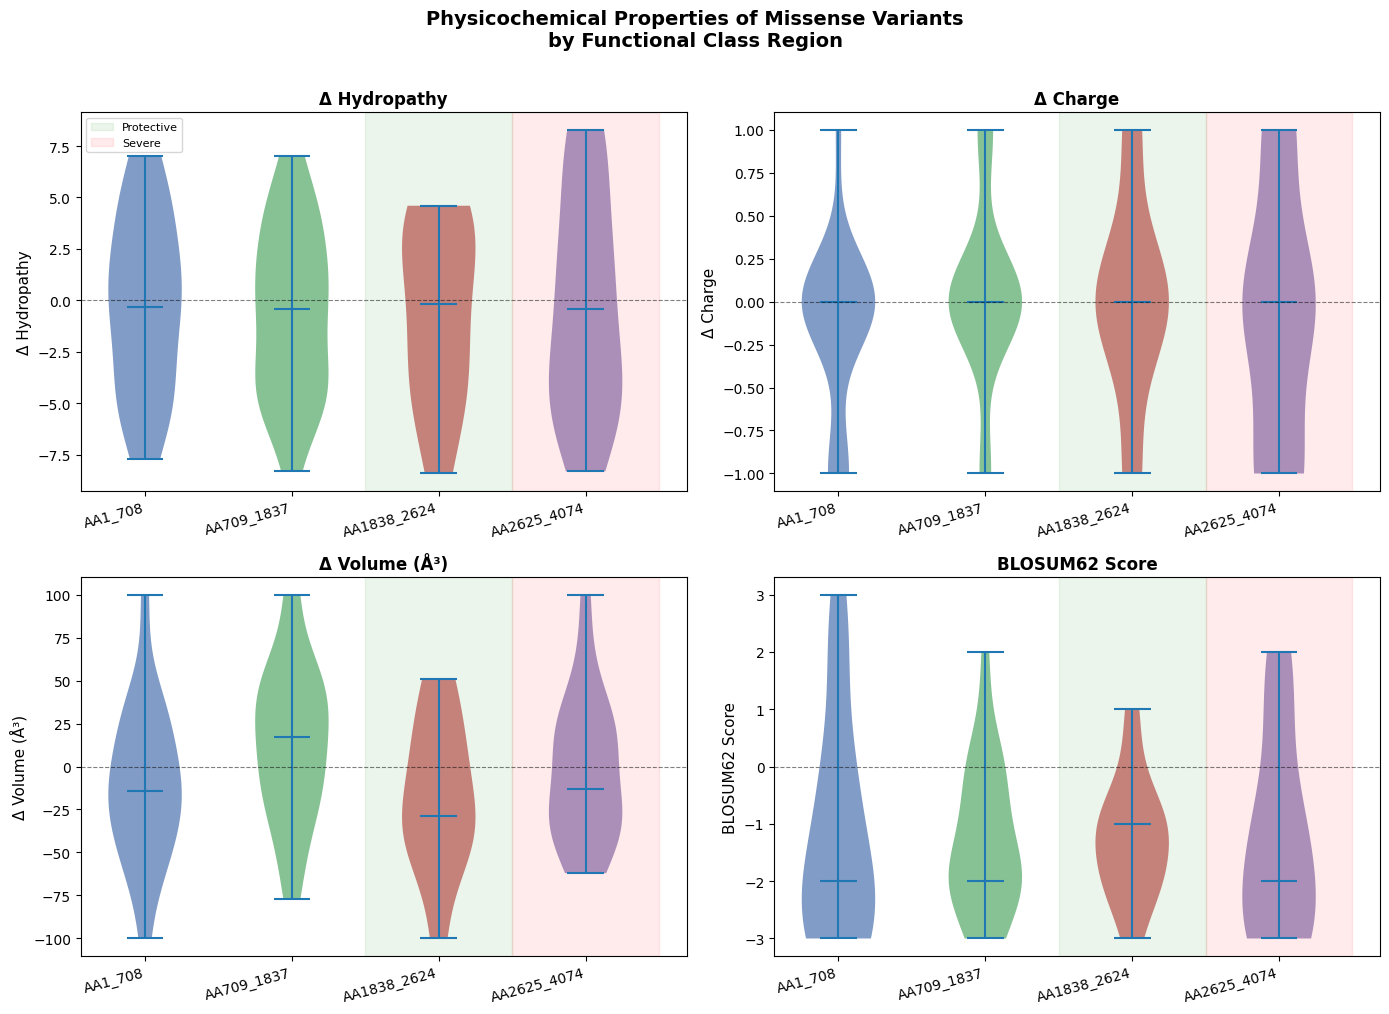


── Mann-Whitney U: Protective (AA1838_2624) vs Severe (AA2625_4074) ──
  Δ Hydropathy            U=116.5  p=0.9352  
  Δ Charge                U=124.0  p=0.6689  
  Δ Volume (Å³)           U=93.0  p=0.4046  
  BLOSUM62 Score          U=125.5  p=0.6465  

── All pairwise Mann-Whitney U (Δ Hydropathy) ──
  AA1_708 vs AA709_1837          U=257.0  p=0.8270  
  AA1_708 vs AA1838_2624         U=117.0  p=0.9192  
  AA1_708 vs AA2625_4074         U=185.5  p=0.8954  
  AA709_1837 vs AA1838_2624         U=150.0  p=0.8627  
  AA709_1837 vs AA2625_4074         U=246.0  p=0.9908  
  AA1838_2624 vs AA2625_4074         U=116.5  p=0.9352  


In [ ]:
import re
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from itertools import combinations

# ── Amino acid property tables ─────────────────────────────────────────────

# Kyte-Doolittle hydropathy
hydropathy = {
    'Ala': 1.8,  'Arg': -4.5, 'Asn': -3.5, 'Asp': -3.5,
    'Cys': 2.5,  'Gln': -3.5, 'Glu': -3.5, 'Gly': -0.4,
    'His': -3.2, 'Ile': 4.5,  'Leu': 3.8,  'Lys': -3.9,
    'Met': 1.9,  'Phe': 2.8,  'Pro': -1.6, 'Ser': -0.8,
    'Thr': -0.7, 'Trp': -0.9, 'Tyr': -1.3, 'Val': 4.2,
}

# Formal charge at physiological pH
charge = {
    'Ala': 0,  'Arg': 1,  'Asn': 0,  'Asp': -1,
    'Cys': 0,  'Gln': 0,  'Glu': -1, 'Gly': 0,
    'His': 0,  'Ile': 0,  'Leu': 0,  'Lys': 1,
    'Met': 0,  'Phe': 0,  'Pro': 0,  'Ser': 0,
    'Thr': 0,  'Trp': 0,  'Tyr': 0,  'Val': 0,
}

# Side chain volume (Å³)
volume = {
    'Ala': 67,  'Arg': 148, 'Asn': 96,  'Asp': 91,
    'Cys': 86,  'Gln': 114, 'Glu': 109, 'Gly': 48,
    'His': 118, 'Ile': 124, 'Leu': 124, 'Lys': 135,
    'Met': 124, 'Phe': 135, 'Pro': 90,  'Ser': 73,
    'Thr': 93,  'Trp': 163, 'Tyr': 141, 'Val': 105,
}

# BLOSUM62 matrix (symmetric, subset of relevant AAs)
blosum62 = {
    ('Ala','Ala'):4,  ('Ala','Arg'):-1, ('Ala','Asn'):-2, ('Ala','Asp'):-2, ('Ala','Cys'):0,
    ('Ala','Gln'):-1, ('Ala','Glu'):-1, ('Ala','Gly'):0,  ('Ala','His'):-2, ('Ala','Ile'):-1,
    ('Ala','Leu'):-1, ('Ala','Lys'):-1, ('Ala','Met'):-1, ('Ala','Phe'):-2, ('Ala','Pro'):-1,
    ('Ala','Ser'):1,  ('Ala','Thr'):0,  ('Ala','Trp'):-3, ('Ala','Tyr'):-2, ('Ala','Val'):0,
    ('Arg','Arg'):5,  ('Arg','Asn'):-1, ('Arg','Asp'):-2, ('Arg','Cys'):-3, ('Arg','Gln'):1,
    ('Arg','Glu'):0,  ('Arg','Gly'):-2, ('Arg','His'):0,  ('Arg','Ile'):-3, ('Arg','Leu'):-2,
    ('Arg','Lys'):2,  ('Arg','Met'):-1, ('Arg','Phe'):-3, ('Arg','Pro'):-2, ('Arg','Ser'):-1,
    ('Arg','Thr'):-1, ('Arg','Trp'):-3, ('Arg','Tyr'):-2, ('Arg','Val'):-3,
    ('Asn','Asn'):6,  ('Asn','Asp'):1,  ('Asn','Cys'):-3, ('Asn','Gln'):0,  ('Asn','Glu'):0,
    ('Asn','Gly'):0,  ('Asn','His'):1,  ('Asn','Ile'):-3, ('Asn','Leu'):-3, ('Asn','Lys'):0,
    ('Asn','Met'):-2, ('Asn','Phe'):-3, ('Asn','Pro'):-2, ('Asn','Ser'):1,  ('Asn','Thr'):0,
    ('Asn','Trp'):-4, ('Asn','Tyr'):-2, ('Asn','Val'):-3,
    ('Asp','Asp'):6,  ('Asp','Cys'):-3, ('Asp','Gln'):0,  ('Asp','Glu'):2,  ('Asp','Gly'):-1,
    ('Asp','His'):-1, ('Asp','Ile'):-3, ('Asp','Leu'):-4, ('Asp','Lys'):-1, ('Asp','Met'):-3,
    ('Asp','Phe'):-3, ('Asp','Pro'):-1, ('Asp','Ser'):0,  ('Asp','Thr'):-1, ('Asp','Trp'):-4,
    ('Asp','Tyr'):-3, ('Asp','Val'):-3,
    ('Cys','Cys'):9,  ('Cys','Gln'):-3, ('Cys','Glu'):-4, ('Cys','Gly'):-3, ('Cys','His'):-3,
    ('Cys','Ile'):-1, ('Cys','Leu'):-1, ('Cys','Lys'):-3, ('Cys','Met'):-1, ('Cys','Phe'):-2,
    ('Cys','Pro'):-3, ('Cys','Ser'):-1, ('Cys','Thr'):-1, ('Cys','Trp'):-2, ('Cys','Tyr'):-2,
    ('Cys','Val'):-1,
    ('Gln','Gln'):5,  ('Gln','Glu'):2,  ('Gln','Gly'):-2, ('Gln','His'):0,  ('Gln','Ile'):-3,
    ('Gln','Leu'):-2, ('Gln','Lys'):1,  ('Gln','Met'):0,  ('Gln','Phe'):-3, ('Gln','Pro'):-1,
    ('Gln','Ser'):0,  ('Gln','Thr'):-1, ('Gln','Trp'):-2, ('Gln','Tyr'):-1, ('Gln','Val'):-2,
    ('Glu','Glu'):5,  ('Glu','Gly'):-2, ('Glu','His'):0,  ('Glu','Ile'):-3, ('Glu','Leu'):-3,
    ('Glu','Lys'):1,  ('Glu','Met'):-2, ('Glu','Phe'):-3, ('Glu','Pro'):-1, ('Glu','Ser'):0,
    ('Glu','Thr'):-1, ('Glu','Trp'):-3, ('Glu','Tyr'):-2, ('Glu','Val'):-2,
    ('Gly','Gly'):6,  ('Gly','His'):-2, ('Gly','Ile'):-4, ('Gly','Leu'):-4, ('Gly','Lys'):-2,
    ('Gly','Met'):-3, ('Gly','Phe'):-3, ('Gly','Pro'):-2, ('Gly','Ser'):0,  ('Gly','Thr'):-2,
    ('Gly','Trp'):-2, ('Gly','Tyr'):-3, ('Gly','Val'):-3,
    ('His','His'):8,  ('His','Ile'):-3, ('His','Leu'):-3, ('His','Lys'):-1, ('His','Met'):-2,
    ('His','Phe'):-1, ('His','Pro'):-2, ('His','Ser'):-1, ('His','Thr'):-2, ('His','Trp'):-2,
    ('His','Tyr'):2,  ('His','Val'):-3,
    ('Ile','Ile'):4,  ('Ile','Leu'):2,  ('Ile','Lys'):-1, ('Ile','Met'):1,  ('Ile','Phe'):0,
    ('Ile','Pro'):-3, ('Ile','Ser'):-2, ('Ile','Thr'):-1, ('Ile','Trp'):-3, ('Ile','Tyr'):-1,
    ('Ile','Val'):3,
    ('Leu','Leu'):4,  ('Leu','Lys'):-2, ('Leu','Met'):2,  ('Leu','Phe'):0,  ('Leu','Pro'):-3,
    ('Leu','Ser'):-2, ('Leu','Thr'):-1, ('Leu','Trp'):-2, ('Leu','Tyr'):-1, ('Leu','Val'):1,
    ('Lys','Lys'):5,  ('Lys','Met'):-1, ('Lys','Phe'):-3, ('Lys','Pro'):-1, ('Lys','Ser'):0,
    ('Lys','Thr'):-1, ('Lys','Trp'):-3, ('Lys','Tyr'):-2, ('Lys','Val'):-2,
    ('Met','Met'):5,  ('Met','Phe'):0,  ('Met','Pro'):-2, ('Met','Ser'):-1, ('Met','Thr'):-1,
    ('Met','Trp'):-1, ('Met','Tyr'):-1, ('Met','Val'):1,
    ('Phe','Phe'):6,  ('Phe','Pro'):-4, ('Phe','Ser'):-2, ('Phe','Thr'):-2, ('Phe','Trp'):1,
    ('Phe','Tyr'):3,  ('Phe','Val'):-1,
    ('Pro','Pro'):7,  ('Pro','Ser'):-1, ('Pro','Thr'):-1, ('Pro','Trp'):-4, ('Pro','Tyr'):-3,
    ('Pro','Val'):-2,
    ('Ser','Ser'):4,  ('Ser','Thr'):1,  ('Ser','Trp'):-3, ('Ser','Tyr'):-2, ('Ser','Val'):-2,
    ('Thr','Thr'):5,  ('Thr','Trp'):-2, ('Thr','Tyr'):-2, ('Thr','Val'):0,
    ('Trp','Trp'):11, ('Trp','Tyr'):2,  ('Trp','Val'):-3,
    ('Tyr','Tyr'):7,  ('Tyr','Val'):-1,
    ('Val','Val'):4,
}

def get_blosum(aa1, aa2):
    if aa1 == aa2:
        return blosum62.get((aa1, aa2), blosum62.get((aa2, aa1), None))
    return blosum62.get((aa1, aa2), blosum62.get((aa2, aa1), None))

# ── Parse ref/alt from missense string ─────────────────────────────────────

def parse_missense(variant):
    """Returns (ref_aa, position, alt_aa) from e.g. p.Ile222Val"""
    m = re.match(r'p\.([A-Z][a-z]{2})(\d+)([A-Z][a-z]{2})$', variant)
    if m:
        return m.group(1), int(m.group(2)), m.group(3)
    return None, None, None

# ── Compute properties for each variant list ───────────────────────────────

def compute_properties(variant_list, region_name):
    records = []
    for v in variant_list:
        ref, pos, alt = parse_missense(v)
        if ref is None or ref not in hydropathy or alt not in hydropathy:
            continue
        delta_hydropathy = hydropathy[alt] - hydropathy[ref]
        delta_charge     = charge[alt]     - charge[ref]
        delta_volume     = volume[alt]     - volume[ref]
        blosum_score     = get_blosum(ref, alt)
        records.append({
            'variant':         v,
            'region':          region_name,
            'ref':             ref,
            'alt':             alt,
            'position':        pos,
            'delta_hydropathy': delta_hydropathy,
            'delta_charge':    delta_charge,
            'delta_volume':    delta_volume,
            'blosum62':        blosum_score,
        })
    return records

all_records = []
region_map = {
    'AA1_708':     missense_AA1_708,
    'AA709_1837':  missense_AA709_1837,
    'AA1838_2624': missense_AA1838_2624,
    'AA2625_4074': missense_AA2625_4074,
}
for region, vlist in region_map.items():
    all_records.extend(compute_properties(vlist, region))

df_props = pd.DataFrame(all_records)
print(df_props.groupby('region')[['delta_hydropathy','delta_charge','delta_volume','blosum62']].describe().round(2))

# ── Violin plots ────────────────────────────────────────────────────────────

metrics = ['delta_hydropathy', 'delta_charge', 'delta_volume', 'blosum62']
labels  = ['Δ Hydropathy', 'Δ Charge', 'Δ Volume (Å³)', 'BLOSUM62 Score']
regions = ['AA1_708', 'AA709_1837', 'AA1838_2624', 'AA2625_4074']
colors  = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']  # blue, green, red, purple

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, metric, label in zip(axes, metrics, labels):
    data = [df_props[df_props['region'] == r][metric].dropna().values for r in regions]
    parts = ax.violinplot(data, positions=range(len(regions)), showmedians=True, showextrema=True)
    for i, (pc, col) in enumerate(zip(parts['bodies'], colors)):
        pc.set_facecolor(col)
        pc.set_alpha(0.7)
    ax.set_xticks(range(len(regions)))
    ax.set_xticklabels(regions, rotation=15, ha='right', fontsize=10)
    ax.set_ylabel(label, fontsize=11)
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    # Annotate protective vs severe
    ax.axvspan(1.5, 2.5, alpha=0.08, color='green', label='Protective')
    ax.axvspan(2.5, 3.5, alpha=0.08, color='red',   label='Severe')
    if metric == 'delta_hydropathy':
        ax.legend(fontsize=8)

plt.suptitle('Physicochemical Properties of Missense Variants\nby Functional Class Region',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('missense_properties_violin.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Mann-Whitney U: AA1838_2624 (protective) vs AA2625_4074 (severe) ───────

print("\n── Mann-Whitney U: Protective (AA1838_2624) vs Severe (AA2625_4074) ──")
for metric, label in zip(metrics, labels):
    a = df_props[df_props['region'] == 'AA1838_2624'][metric].dropna()
    b = df_props[df_props['region'] == 'AA2625_4074'][metric].dropna()
    if len(a) > 1 and len(b) > 1:
        stat, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        print(f"  {label:<22}  U={stat:.1f}  p={p:.4f}  {'*' if p<0.05 else ''}")

# ── All pairwise comparisons ────────────────────────────────────────────────

print("\n── All pairwise Mann-Whitney U (Δ Hydropathy) ──")
for r1, r2 in combinations(regions, 2):
    a = df_props[df_props['region'] == r1]['delta_hydropathy'].dropna()
    b = df_props[df_props['region'] == r2]['delta_hydropathy'].dropna()
    stat, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    print(f"  {r1} vs {r2:<18}  U={stat:.1f}  p={p:.4f}  {'*' if p<0.05 else ''}")

# **Clinical validations**

Patient counts per region:
region
AA1838_2624    22
AA1_708        44
AA2625_4074    21
AA709_1837     51
dtype: int64

Event rates per region:
             had_krt  had_portal_htn  had_hepatic
region                                           
AA1838_2624    0.227           0.227        0.045
AA1_708        0.364           0.455        0.114
AA2625_4074    0.286           0.762        0.381
AA709_1837     0.078           0.333        0.059

── Full summary ──
              n  krt_rate  portal_htn_rate  hepatic_rate  hepatic_only_rate  renal_only_rate  both_events_rate  no_events_rate  median_krt_age  median_hepatic_age
region                                                                                                                                                            
AA1838_2624  22     0.227            0.227         0.045              0.000            0.182             0.045           0.773          10.170               11.00
AA1_708      44     0.364            0.455     

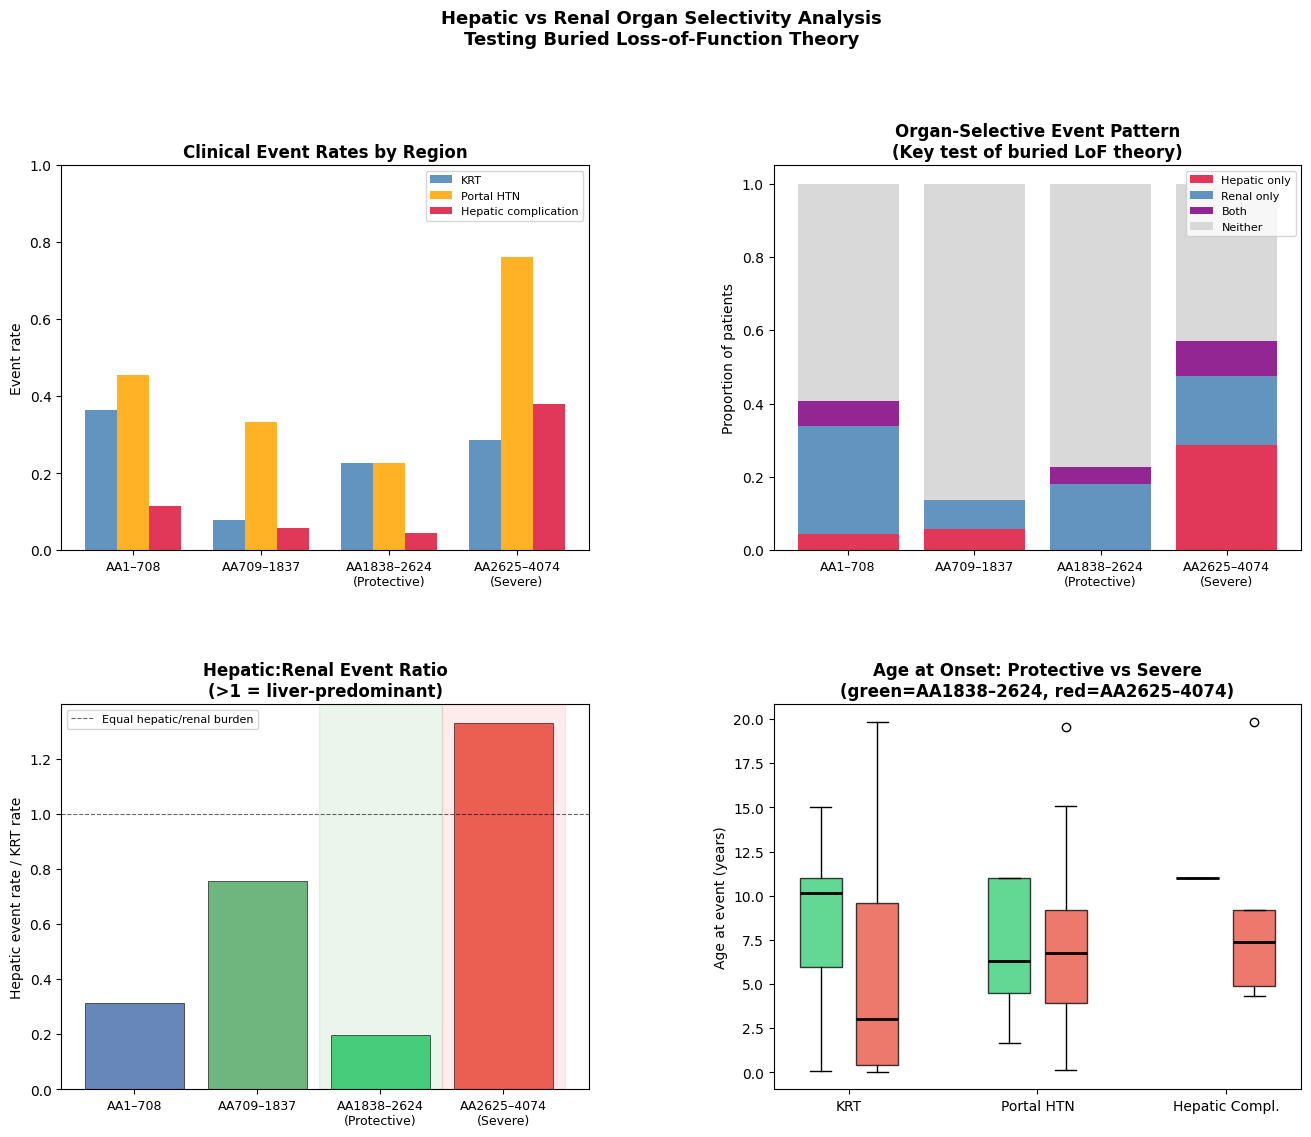

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from matplotlib.gridspec import GridSpec

# ── Load and combine all 4 files ───────────────────────────────────────────
files = {
    "AA1_708":     "Burgmaier_Genotype_Phenotype_Replication - AA1-708.csv",
    "AA709_1837":  "Burgmaier_Genotype_Phenotype_Replication - AA709-1837.csv",
    "AA1838_2624": "Burgmaier_Genotype_Phenotype_Replication - AA1838-2624.csv",
    "AA2625_4074": "Burgmaier_Genotype_Phenotype_Replication - AA2625-4074.csv",
}

dfs = []
for region, fpath in files.items():
    df = pd.read_csv(fpath)
    df['region'] = region
    dfs.append(df)

data = pd.concat(dfs, ignore_index=True)

# ── Parse clinical columns ─────────────────────────────────────────────────
# Convert to numeric, coerce errors to NaN (handles '-', '#ERROR!', etc.)

def to_numeric(col):
    return pd.to_numeric(col, errors='coerce')

# KRT: kidney replacement therapy onset age
# Portal HTN onset age
# Substantial hepatic complication onset age
# Last follow-up age

data['krt_age']        = to_numeric(data.iloc[:, 2])   # KRT age
data['portal_htn_age'] = to_numeric(data.iloc[:, 3])   # Portal HTN age
data['hepatic_age']    = to_numeric(data.iloc[:, 4])   # Substantial hepatic complication
data['followup_age']   = to_numeric(data.iloc[:, 5].astype(str).str.extract(r'([\d.]+)')[0])

# Binary event flags (event occurred = 1, censored = 0)
data['had_krt']        = data['krt_age'].notna().astype(int)
data['had_portal_htn'] = data['portal_htn_age'].notna().astype(int)
data['had_hepatic']    = data['hepatic_age'].notna().astype(int)

# Hepatic/renal ratio per patient
# 1 = hepatic event only, -1 = renal only, 0 = both or neither
data['hepatic_only']   = ((data['had_hepatic'] == 1) & (data['had_krt'] == 0)).astype(int)
data['renal_only']     = ((data['had_krt'] == 1)     & (data['had_hepatic'] == 0)).astype(int)
data['both_events']    = ((data['had_krt'] == 1)     & (data['had_hepatic'] == 1)).astype(int)
data['no_events']      = ((data['had_krt'] == 0)     & (data['had_hepatic'] == 0)).astype(int)

print("Patient counts per region:")
print(data.groupby('region').size())
print("\nEvent rates per region:")
print(data.groupby('region')[['had_krt','had_portal_htn','had_hepatic']].mean().round(3))

# ── Summary table ──────────────────────────────────────────────────────────

summary = data.groupby('region').agg(
    n                   = ('region', 'count'),
    krt_rate            = ('had_krt', 'mean'),
    portal_htn_rate     = ('had_portal_htn', 'mean'),
    hepatic_rate        = ('had_hepatic', 'mean'),
    hepatic_only_rate   = ('hepatic_only', 'mean'),
    renal_only_rate     = ('renal_only', 'mean'),
    both_events_rate    = ('both_events', 'mean'),
    no_events_rate      = ('no_events', 'mean'),
    median_krt_age      = ('krt_age', 'median'),
    median_hepatic_age  = ('hepatic_age', 'median'),
).round(3)

print("\n── Full summary ──")
print(summary.to_string())

# ── Statistical tests: AA1838_2624 vs AA2625_4074 ─────────────────────────

protective = data[data['region'] == 'AA1838_2624']
severe     = data[data['region'] == 'AA2625_4074']

print("\n── Fisher's Exact: Protective (AA1838_2624) vs Severe (AA2625_4074) ──")
for event, label in [('had_hepatic', 'Hepatic complication'),
                     ('had_portal_htn', 'Portal hypertension'),
                     ('had_krt', 'KRT')]:
    a = protective[event].values
    b = severe[event].values
    table = [[sum(a==1), sum(a==0)],
             [sum(b==1), sum(b==0)]]
    OR, p = stats.fisher_exact(table)
    print(f"  {label:<28} OR={OR:.2f}  p={p:.4f}  {'*' if p<0.05 else ''}")

# Onset age comparison (Mann-Whitney)
print("\n── Mann-Whitney U: Age at onset ──")
for age_col, label in [('krt_age', 'KRT onset age'),
                       ('hepatic_age', 'Hepatic complication age'),
                       ('portal_htn_age', 'Portal HTN age')]:
    a = protective[age_col].dropna()
    b = severe[age_col].dropna()
    if len(a) > 1 and len(b) > 1:
        stat, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        print(f"  {label:<28} n={len(a)}/{len(b)}  U={stat:.1f}  p={p:.4f}  {'*' if p<0.05 else ''}")
    else:
        print(f"  {label:<28} insufficient data (n={len(a)}/{len(b)})")

# ── Visualisation ──────────────────────────────────────────────────────────

regions      = ['AA1_708', 'AA709_1837', 'AA1838_2624', 'AA2625_4074']
region_labels = ['AA1–708', 'AA709–1837', 'AA1838–2624\n(Protective)', 'AA2625–4074\n(Severe)']
colors        = ['#4C72B0', '#55A868', '#2ecc71', '#e74c3c']

fig = plt.figure(figsize=(16, 12))
gs  = GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

# ── Plot 1: Event rates bar chart ──
ax1 = fig.add_subplot(gs[0, 0])
x   = np.arange(len(regions))
w   = 0.25
krt_rates     = [summary.loc[r, 'krt_rate']    for r in regions]
hepatic_rates = [summary.loc[r, 'hepatic_rate'] for r in regions]
portal_rates  = [summary.loc[r, 'portal_htn_rate'] for r in regions]

ax1.bar(x - w, krt_rates,     width=w, label='KRT',                  color='steelblue', alpha=0.85)
ax1.bar(x,     portal_rates,  width=w, label='Portal HTN',           color='orange',    alpha=0.85)
ax1.bar(x + w, hepatic_rates, width=w, label='Hepatic complication', color='crimson',   alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(region_labels, fontsize=9)
ax1.set_ylabel('Event rate')
ax1.set_title('Clinical Event Rates by Region', fontweight='bold')
ax1.legend(fontsize=8)
ax1.set_ylim(0, 1)

# ── Plot 2: Hepatic vs Renal organ selectivity stacked bar ──
ax2 = fig.add_subplot(gs[0, 1])
hepatic_only = [summary.loc[r, 'hepatic_only_rate'] for r in regions]
renal_only   = [summary.loc[r, 'renal_only_rate']   for r in regions]
both         = [summary.loc[r, 'both_events_rate']  for r in regions]
neither      = [summary.loc[r, 'no_events_rate']    for r in regions]

ax2.bar(x, hepatic_only, label='Hepatic only', color='crimson',   alpha=0.85)
ax2.bar(x, renal_only,   label='Renal only',   color='steelblue', alpha=0.85, bottom=hepatic_only)
ax2.bar(x, both,         label='Both',         color='purple',    alpha=0.85,
        bottom=[h+r for h,r in zip(hepatic_only, renal_only)])
ax2.bar(x, neither,      label='Neither',      color='lightgrey', alpha=0.85,
        bottom=[h+r+b for h,r,b in zip(hepatic_only, renal_only, both)])
ax2.set_xticks(x)
ax2.set_xticklabels(region_labels, fontsize=9)
ax2.set_ylabel('Proportion of patients')
ax2.set_title('Organ-Selective Event Pattern\n(Key test of buried LoF theory)', fontweight='bold')
ax2.legend(fontsize=8)

# ── Plot 3: Hepatic/renal event ratio (hepatic rate / krt rate) ──
ax3 = fig.add_subplot(gs[1, 0])
hepatic_renal_ratio = []
for r in regions:
    h = summary.loc[r, 'hepatic_rate']
    k = summary.loc[r, 'krt_rate']
    ratio = h / k if k > 0 else np.nan
    hepatic_renal_ratio.append(ratio)

bars = ax3.bar(x, hepatic_renal_ratio, color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
ax3.axhline(1.0, color='black', linestyle='--', linewidth=0.8, alpha=0.6, label='Equal hepatic/renal burden')
ax3.set_xticks(x)
ax3.set_xticklabels(region_labels, fontsize=9)
ax3.set_ylabel('Hepatic event rate / KRT rate')
ax3.set_title('Hepatic:Renal Event Ratio\n(>1 = liver-predominant)', fontweight='bold')
ax3.legend(fontsize=8)
# Shade protective vs severe
ax3.axvspan(1.5, 2.5, alpha=0.08, color='green')
ax3.axvspan(2.5, 3.5, alpha=0.08, color='red')

# ── Plot 4: Onset age comparison (protective vs severe) ──
ax4 = fig.add_subplot(gs[1, 1])
age_data = {
    'KRT':     [protective['krt_age'].dropna().values,     severe['krt_age'].dropna().values],
    'Portal\nHTN': [protective['portal_htn_age'].dropna().values, severe['portal_htn_age'].dropna().values],
    'Hepatic\nCompl.': [protective['hepatic_age'].dropna().values,  severe['hepatic_age'].dropna().values],
}
positions = [1, 1.6, 3, 3.6, 5, 5.6]
plot_colors = ['#2ecc71','#e74c3c'] * 3
all_data = [v for vals in age_data.values() for v in vals]
bp = ax4.boxplot(all_data, positions=positions, widths=0.45, patch_artist=True,
                 medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], plot_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax4.set_xticks([1.3, 3.3, 5.3])
ax4.set_xticklabels(['KRT', 'Portal HTN', 'Hepatic Compl.'], fontsize=10)
ax4.set_ylabel('Age at event (years)')
ax4.set_title('Age at Onset: Protective vs Severe\n(green=AA1838–2624, red=AA2625–4074)', fontweight='bold')

plt.suptitle('Hepatic vs Renal Organ Selectivity Analysis\nTesting Buried Loss-of-Function Theory',
             fontsize=13, fontweight='bold', y=1.01)
plt.savefig('buried_lof_organ_selectivity.png', dpi=150, bbox_inches='tight')
plt.show()

              n  krt_rate  portal_htn_rate  hepatic_rate  hepatic_only_rate  renal_only_rate  both_rate  no_events_rate
region                                                                                                                 
AA1838_2624  22     0.227            0.227         0.045              0.000            0.182      0.045           0.773
AA1_708      44     0.364            0.455         0.114              0.045            0.295      0.068           0.591
AA2625_4074  21     0.286            0.762         0.381              0.286            0.190      0.095           0.429
AA709_1837   51     0.078            0.333         0.059              0.059            0.078      0.000           0.863
Null_Null    13     0.615            0.692         0.231              0.000            0.385      0.231           0.385

── Fisher's Exact: Null/Null vs AA2625_4074 ──
  Hepatic complication         OR=0.49  p=0.4653  ns
  Portal hypertension          OR=0.70  p=0.7041  ns
  KRT 

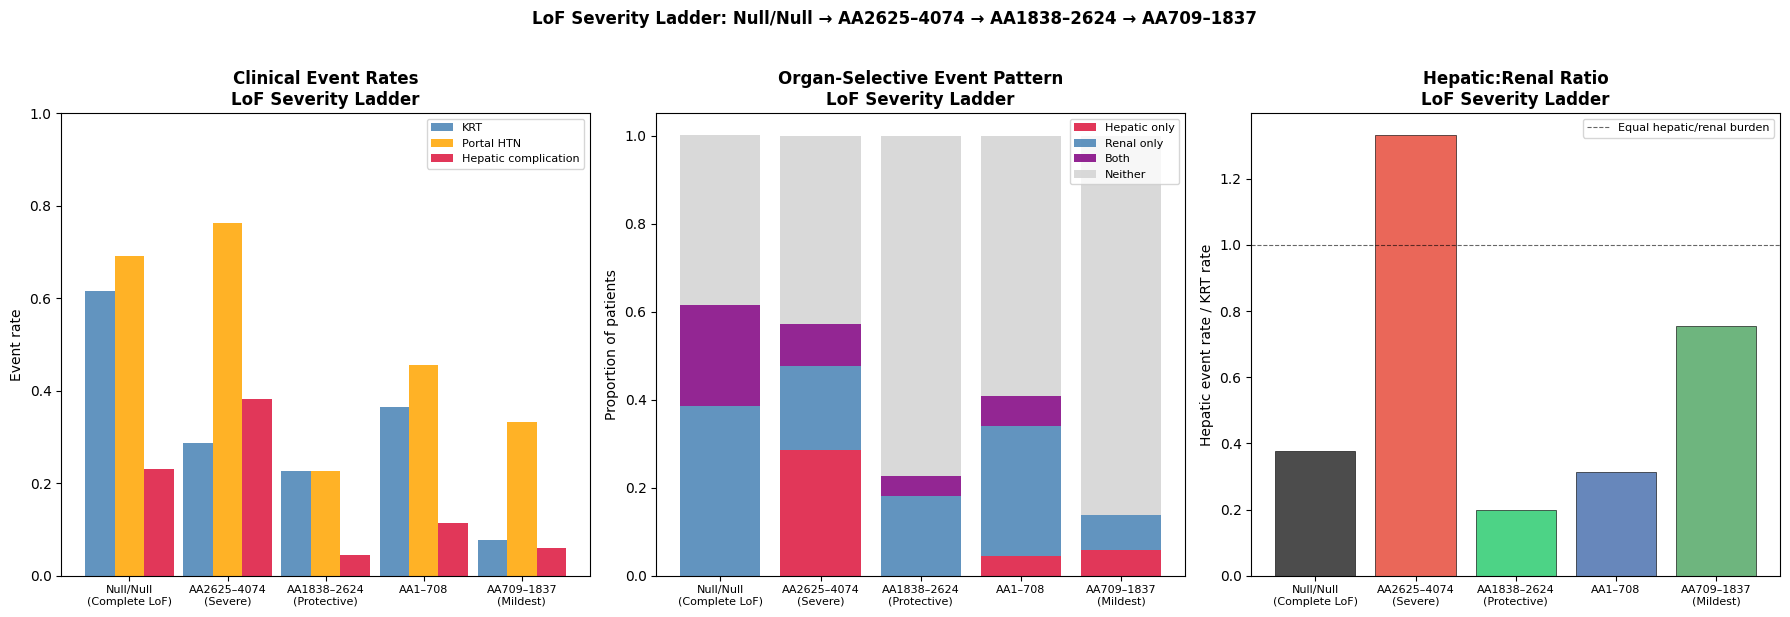

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# ── Load Null/Null ─────────────────────────────────────────────────────────

null_null = pd.read_csv("/content/Burgmaier_Genotype_Phenotype_Replication - Null_Null.csv")

def to_numeric(col):
    return pd.to_numeric(col, errors='coerce')

null_null['krt_age']        = to_numeric(null_null['KRT (age at onset, yrs)'])
null_null['portal_htn_age'] = to_numeric(null_null['Portal HTN during disease course (age, yrs)'])
null_null['hepatic_age']    = to_numeric(null_null['Substan- tial hepatic compli- cation during disease course (age, yrs)'])
null_null['followup_age']   = to_numeric(null_null['Last follow- up (age, yrs), Death'].astype(str).str.extract(r'([\d.]+)')[0])
null_null['region']         = 'Null_Null'

null_null['had_krt']        = null_null['krt_age'].notna().astype(int)
null_null['had_portal_htn'] = null_null['portal_htn_age'].notna().astype(int)
null_null['had_hepatic']    = null_null['hepatic_age'].notna().astype(int)
null_null['hepatic_only']   = ((null_null['had_hepatic'] == 1) & (null_null['had_krt'] == 0)).astype(int)
null_null['renal_only']     = ((null_null['had_krt'] == 1)     & (null_null['had_hepatic'] == 0)).astype(int)
null_null['both_events']    = ((null_null['had_krt'] == 1)     & (null_null['had_hepatic'] == 1)).astype(int)
null_null['no_events']      = ((null_null['had_krt'] == 0)     & (null_null['had_hepatic'] == 0)).astype(int)

# ── Combine with existing data, add Null/Null to ladder ───────────────────

# Re-use 'data' df from previous snippet, just add Null/Null
cols = ['region','had_krt','had_portal_htn','had_hepatic',
        'hepatic_only','renal_only','both_events','no_events',
        'krt_age','portal_htn_age','hepatic_age']

combined = pd.concat([data[cols], null_null[cols]], ignore_index=True)

# ── Summary ───────────────────────────────────────────────────────────────

summary_full = combined.groupby('region').agg(
    n                 = ('region', 'count'),
    krt_rate          = ('had_krt', 'mean'),
    portal_htn_rate   = ('had_portal_htn', 'mean'),
    hepatic_rate      = ('had_hepatic', 'mean'),
    hepatic_only_rate = ('hepatic_only', 'mean'),
    renal_only_rate   = ('renal_only', 'mean'),
    both_rate         = ('both_events', 'mean'),
    no_events_rate    = ('no_events', 'mean'),
).round(3)

print(summary_full.to_string())

# ── Ordered ladder for plots ───────────────────────────────────────────────

ladder  = ['Null_Null', 'AA2625_4074', 'AA1838_2624', 'AA1_708', 'AA709_1837']
labels  = ['Null/Null\n(Complete LoF)', 'AA2625–4074\n(Severe)',
           'AA1838–2624\n(Protective)', 'AA1–708', 'AA709–1837\n(Mildest)']
colors  = ['#2c2c2c', '#e74c3c', '#2ecc71', '#4C72B0', '#55A868']

# ── Plots ──────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# ── Plot 1: Hepatic vs KRT event rates across ladder ──
ax = axes[0]
x  = np.arange(len(ladder))
w  = 0.3
krt_rates     = [summary_full.loc[r, 'krt_rate']      for r in ladder]
hepatic_rates = [summary_full.loc[r, 'hepatic_rate']  for r in ladder]
portal_rates  = [summary_full.loc[r, 'portal_htn_rate'] for r in ladder]

ax.bar(x - w, krt_rates,     width=w, label='KRT',                  color='steelblue', alpha=0.85)
ax.bar(x,     portal_rates,  width=w, label='Portal HTN',           color='orange',    alpha=0.85)
ax.bar(x + w, hepatic_rates, width=w, label='Hepatic complication', color='crimson',   alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Event rate')
ax.set_title('Clinical Event Rates\nLoF Severity Ladder', fontweight='bold')
ax.legend(fontsize=8)
ax.set_ylim(0, 1)

# ── Plot 2: Organ selectivity stacked bar ──
ax = axes[1]
hepatic_only = [summary_full.loc[r, 'hepatic_only_rate'] for r in ladder]
renal_only   = [summary_full.loc[r, 'renal_only_rate']   for r in ladder]
both         = [summary_full.loc[r, 'both_rate']         for r in ladder]
neither      = [summary_full.loc[r, 'no_events_rate']    for r in ladder]

ax.bar(x, hepatic_only, label='Hepatic only', color='crimson',   alpha=0.85)
ax.bar(x, renal_only,   label='Renal only',   color='steelblue', alpha=0.85,
       bottom=hepatic_only)
ax.bar(x, both,         label='Both',         color='purple',    alpha=0.85,
       bottom=[h+r for h,r in zip(hepatic_only, renal_only)])
ax.bar(x, neither,      label='Neither',      color='lightgrey', alpha=0.85,
       bottom=[h+r+b for h,r,b in zip(hepatic_only, renal_only, both)])
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Proportion of patients')
ax.set_title('Organ-Selective Event Pattern\nLoF Severity Ladder', fontweight='bold')
ax.legend(fontsize=8)

# ── Plot 3: Hepatic:Renal ratio across ladder ──
ax = axes[2]
ratios = []
for r in ladder:
    h = summary_full.loc[r, 'hepatic_rate']
    k = summary_full.loc[r, 'krt_rate']
    ratios.append(h / k if k > 0 else np.nan)

bars = ax.bar(x, ratios, color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)
ax.axhline(1.0, color='black', linestyle='--', linewidth=0.8, alpha=0.6,
           label='Equal hepatic/renal burden')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Hepatic event rate / KRT rate')
ax.set_title('Hepatic:Renal Ratio\nLoF Severity Ladder', fontweight='bold')
ax.legend(fontsize=8)

# ── Fisher's exact: Null/Null vs AA2625_4074 ──────────────────────────────

print("\n── Fisher's Exact: Null/Null vs AA2625_4074 ──")
nn  = combined[combined['region'] == 'Null_Null']
sev = combined[combined['region'] == 'AA2625_4074']
for event, label in [('had_hepatic',    'Hepatic complication'),
                     ('had_portal_htn', 'Portal hypertension'),
                     ('had_krt',        'KRT')]:
    a = nn[event].values
    b = sev[event].values
    table = [[sum(a==1), sum(a==0)],
             [sum(b==1), sum(b==0)]]
    OR, p = stats.fisher_exact(table)
    print(f"  {label:<28} OR={OR:.2f}  p={p:.4f}  {'*' if p<0.05 else 'ns'}")

plt.suptitle('LoF Severity Ladder: Null/Null → AA2625–4074 → AA1838–2624 → AA709–1837',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('lof_severity_ladder.png', dpi=150, bbox_inches='tight')
plt.show()

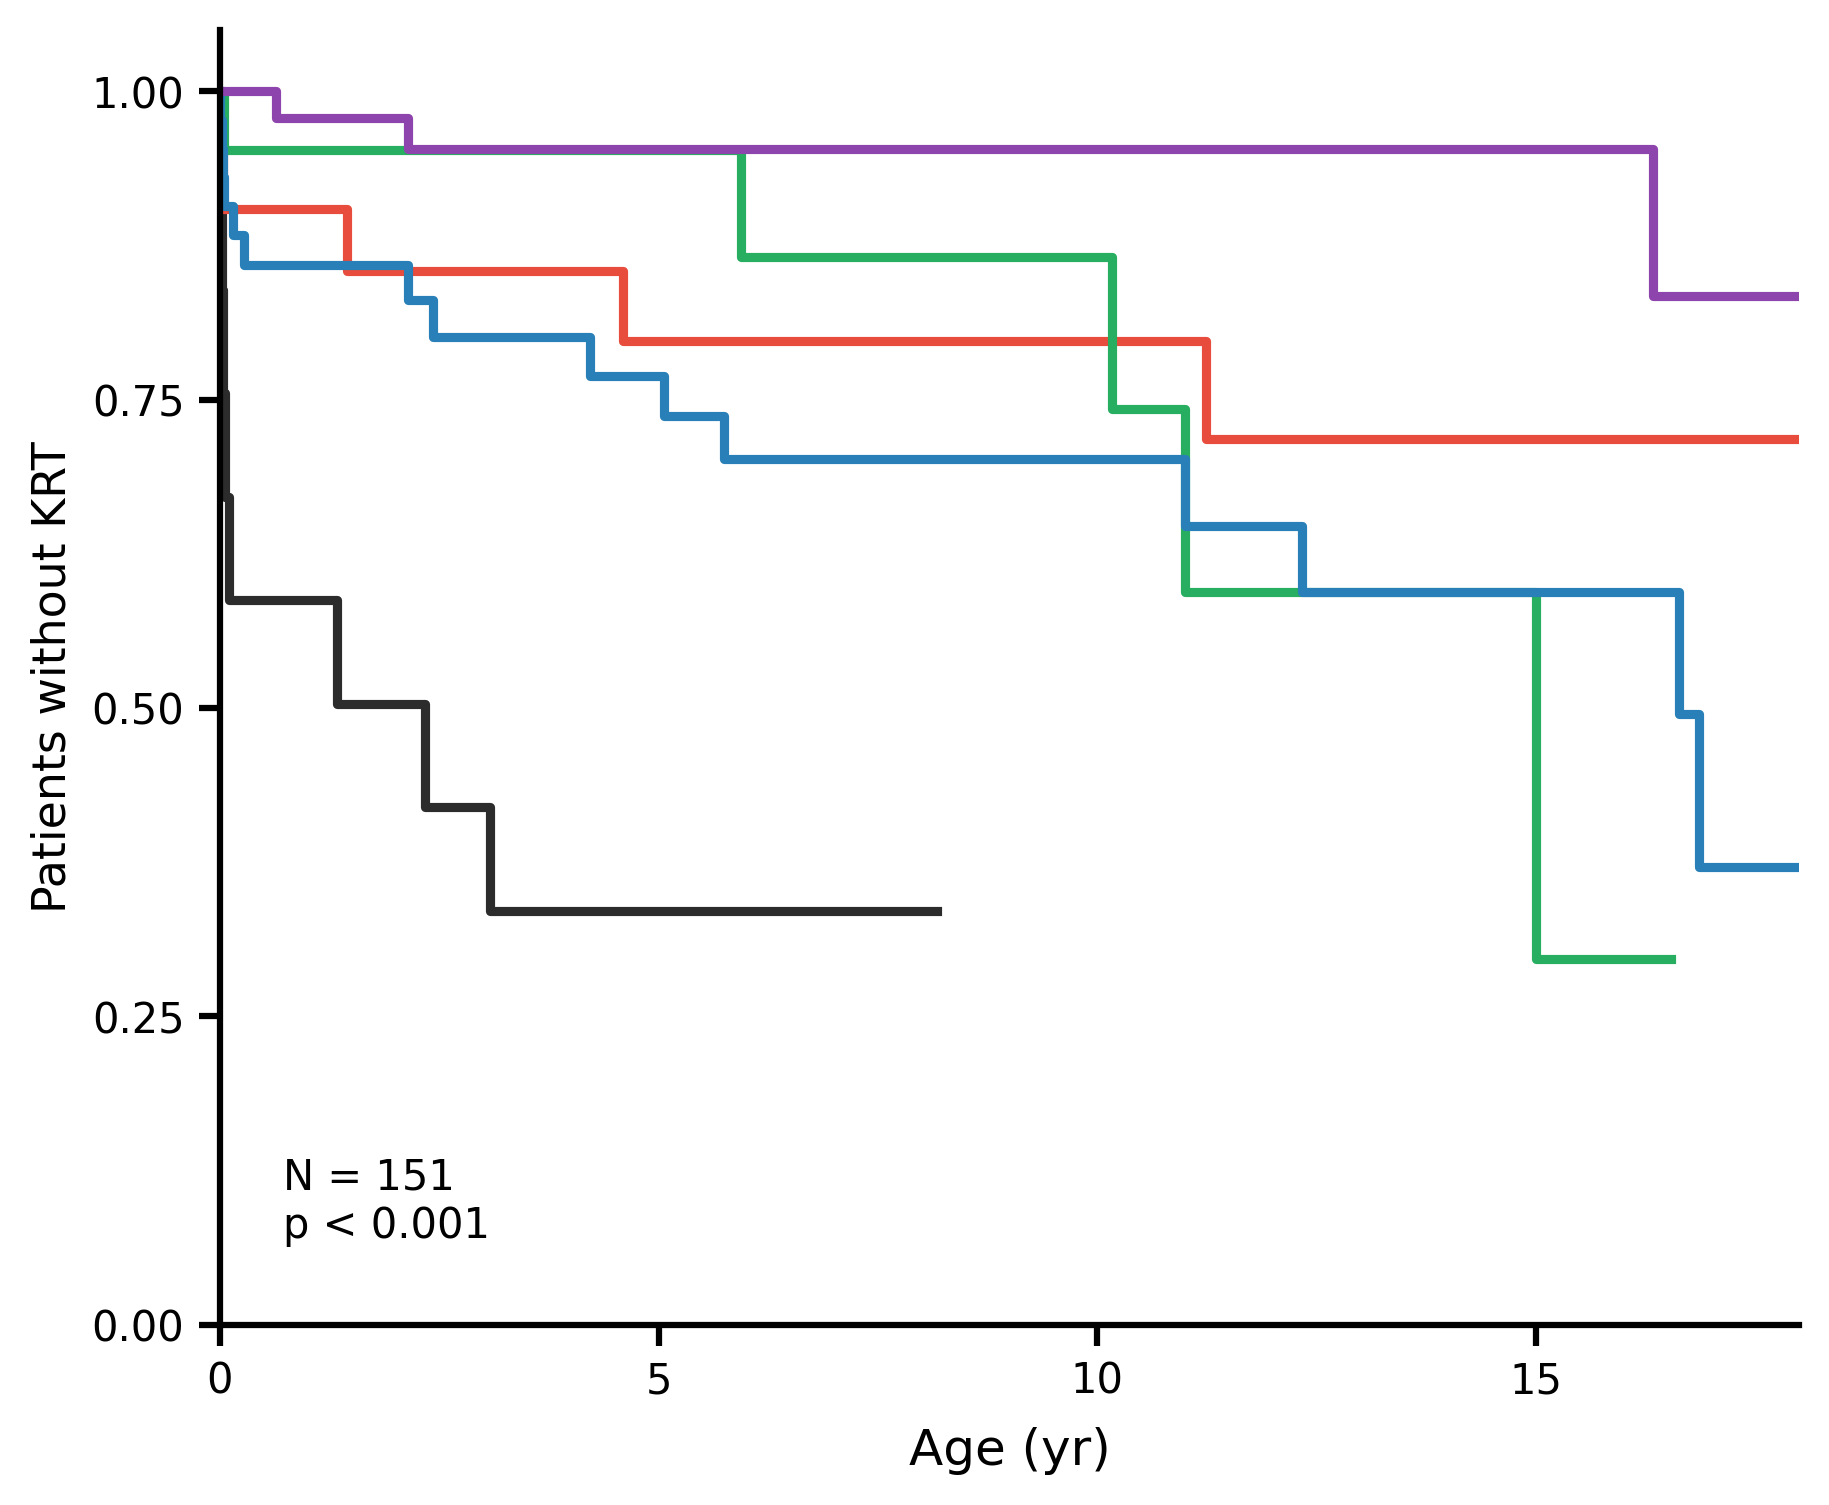

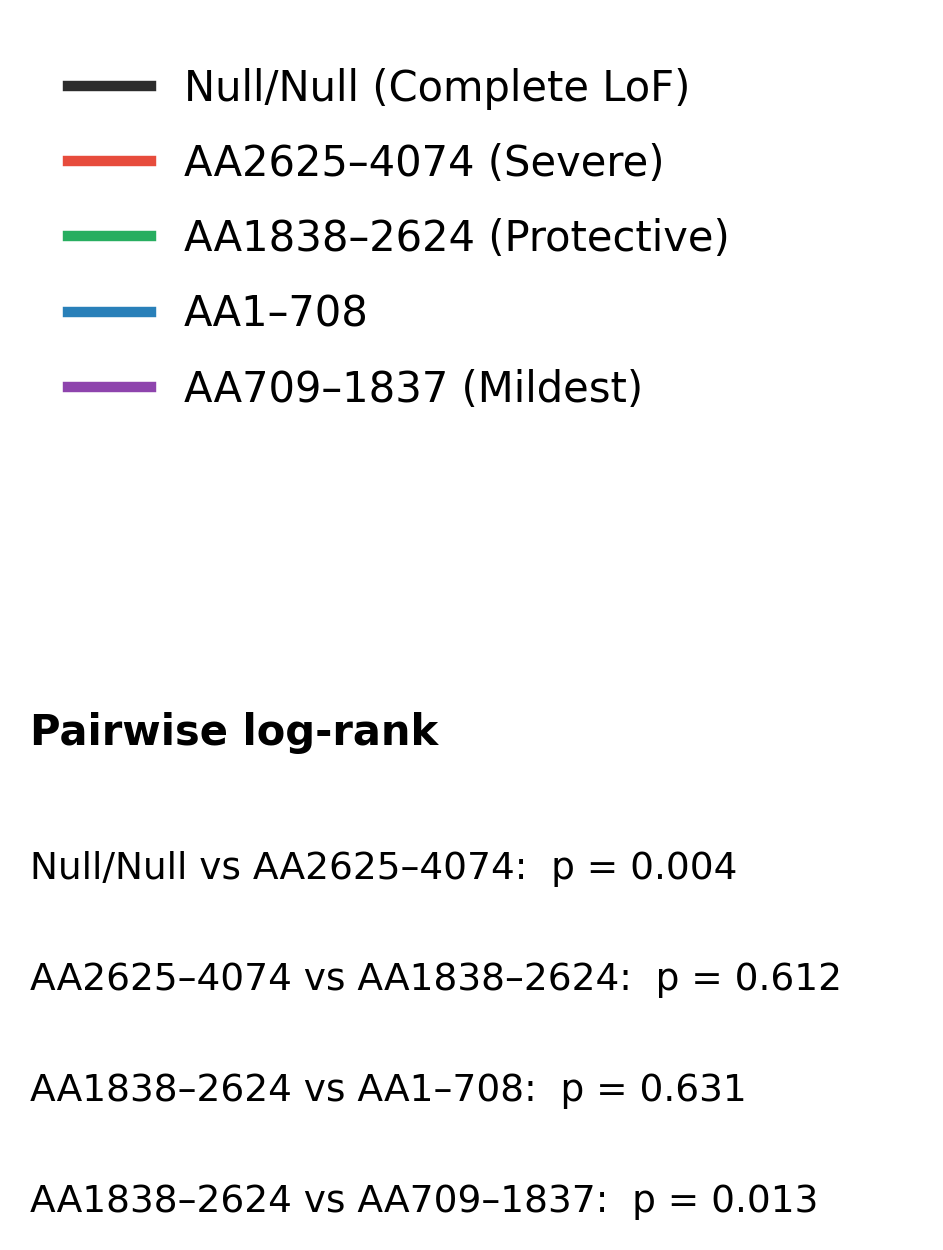

Saved: km_krt_with_null.png
Saved: km_krt_with_null_legend.png


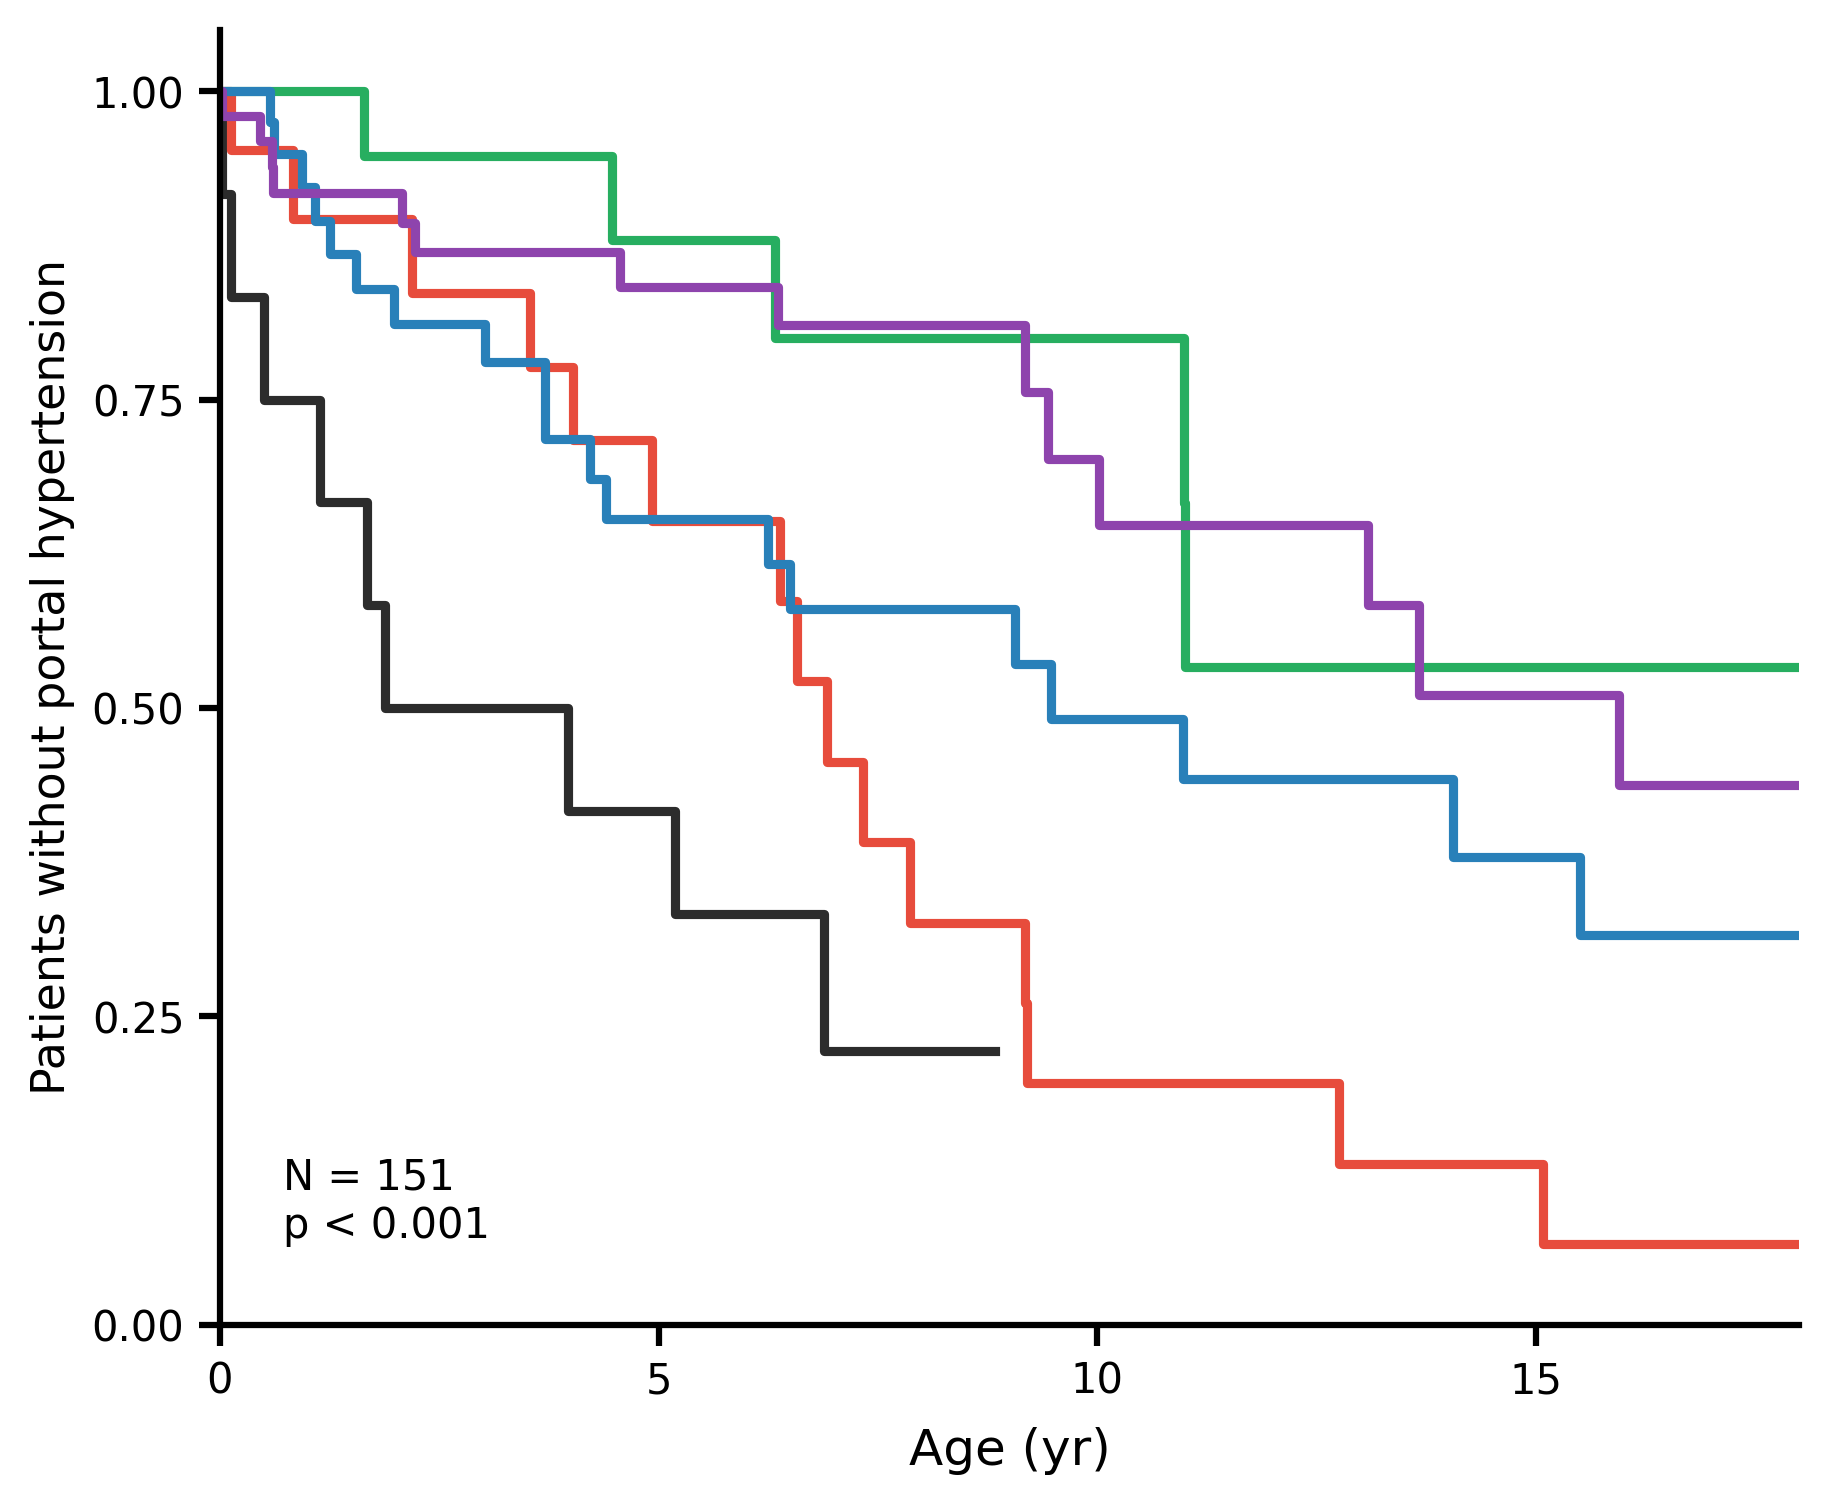

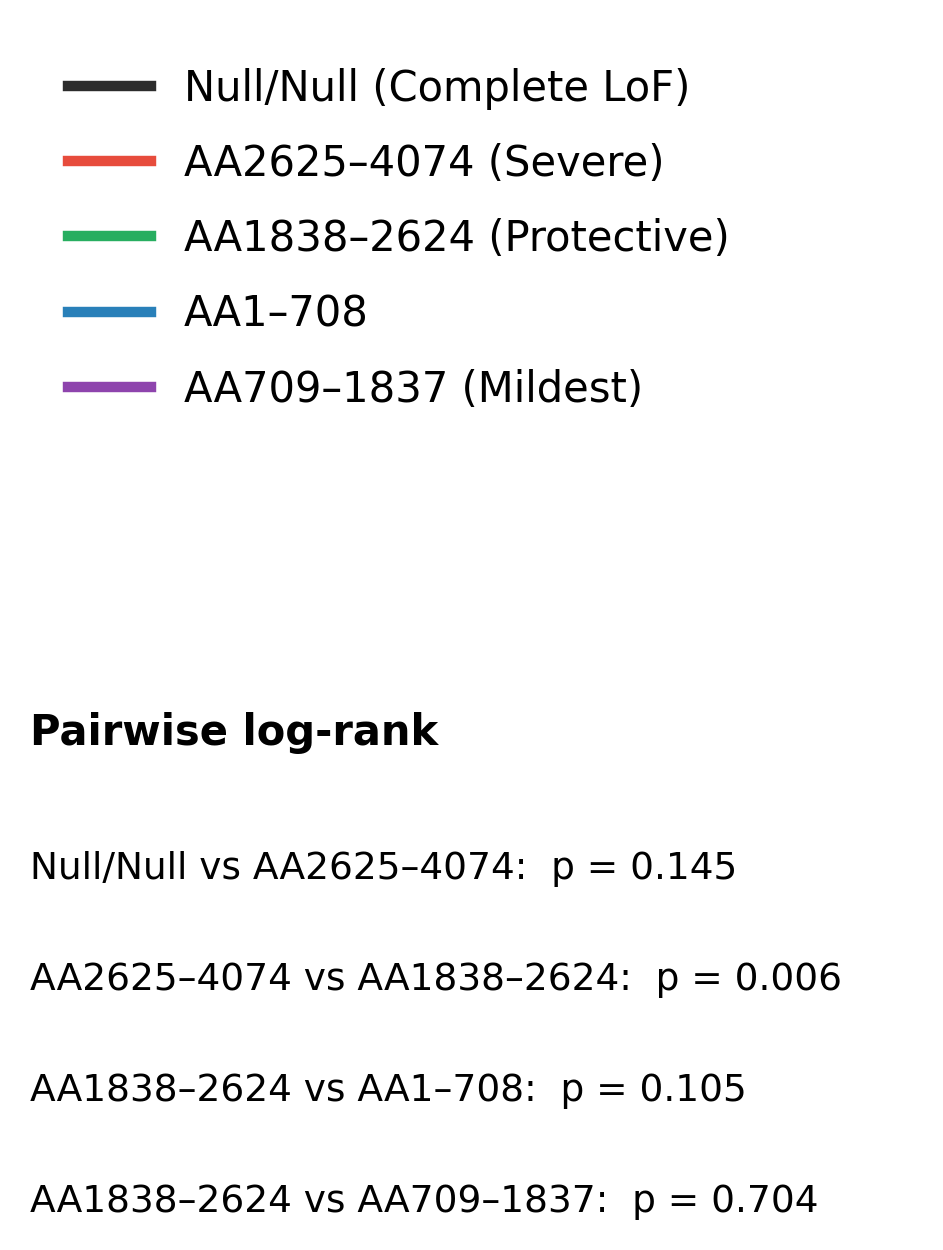

Saved: km_portal_htn_with_null.png
Saved: km_portal_htn_with_null_legend.png


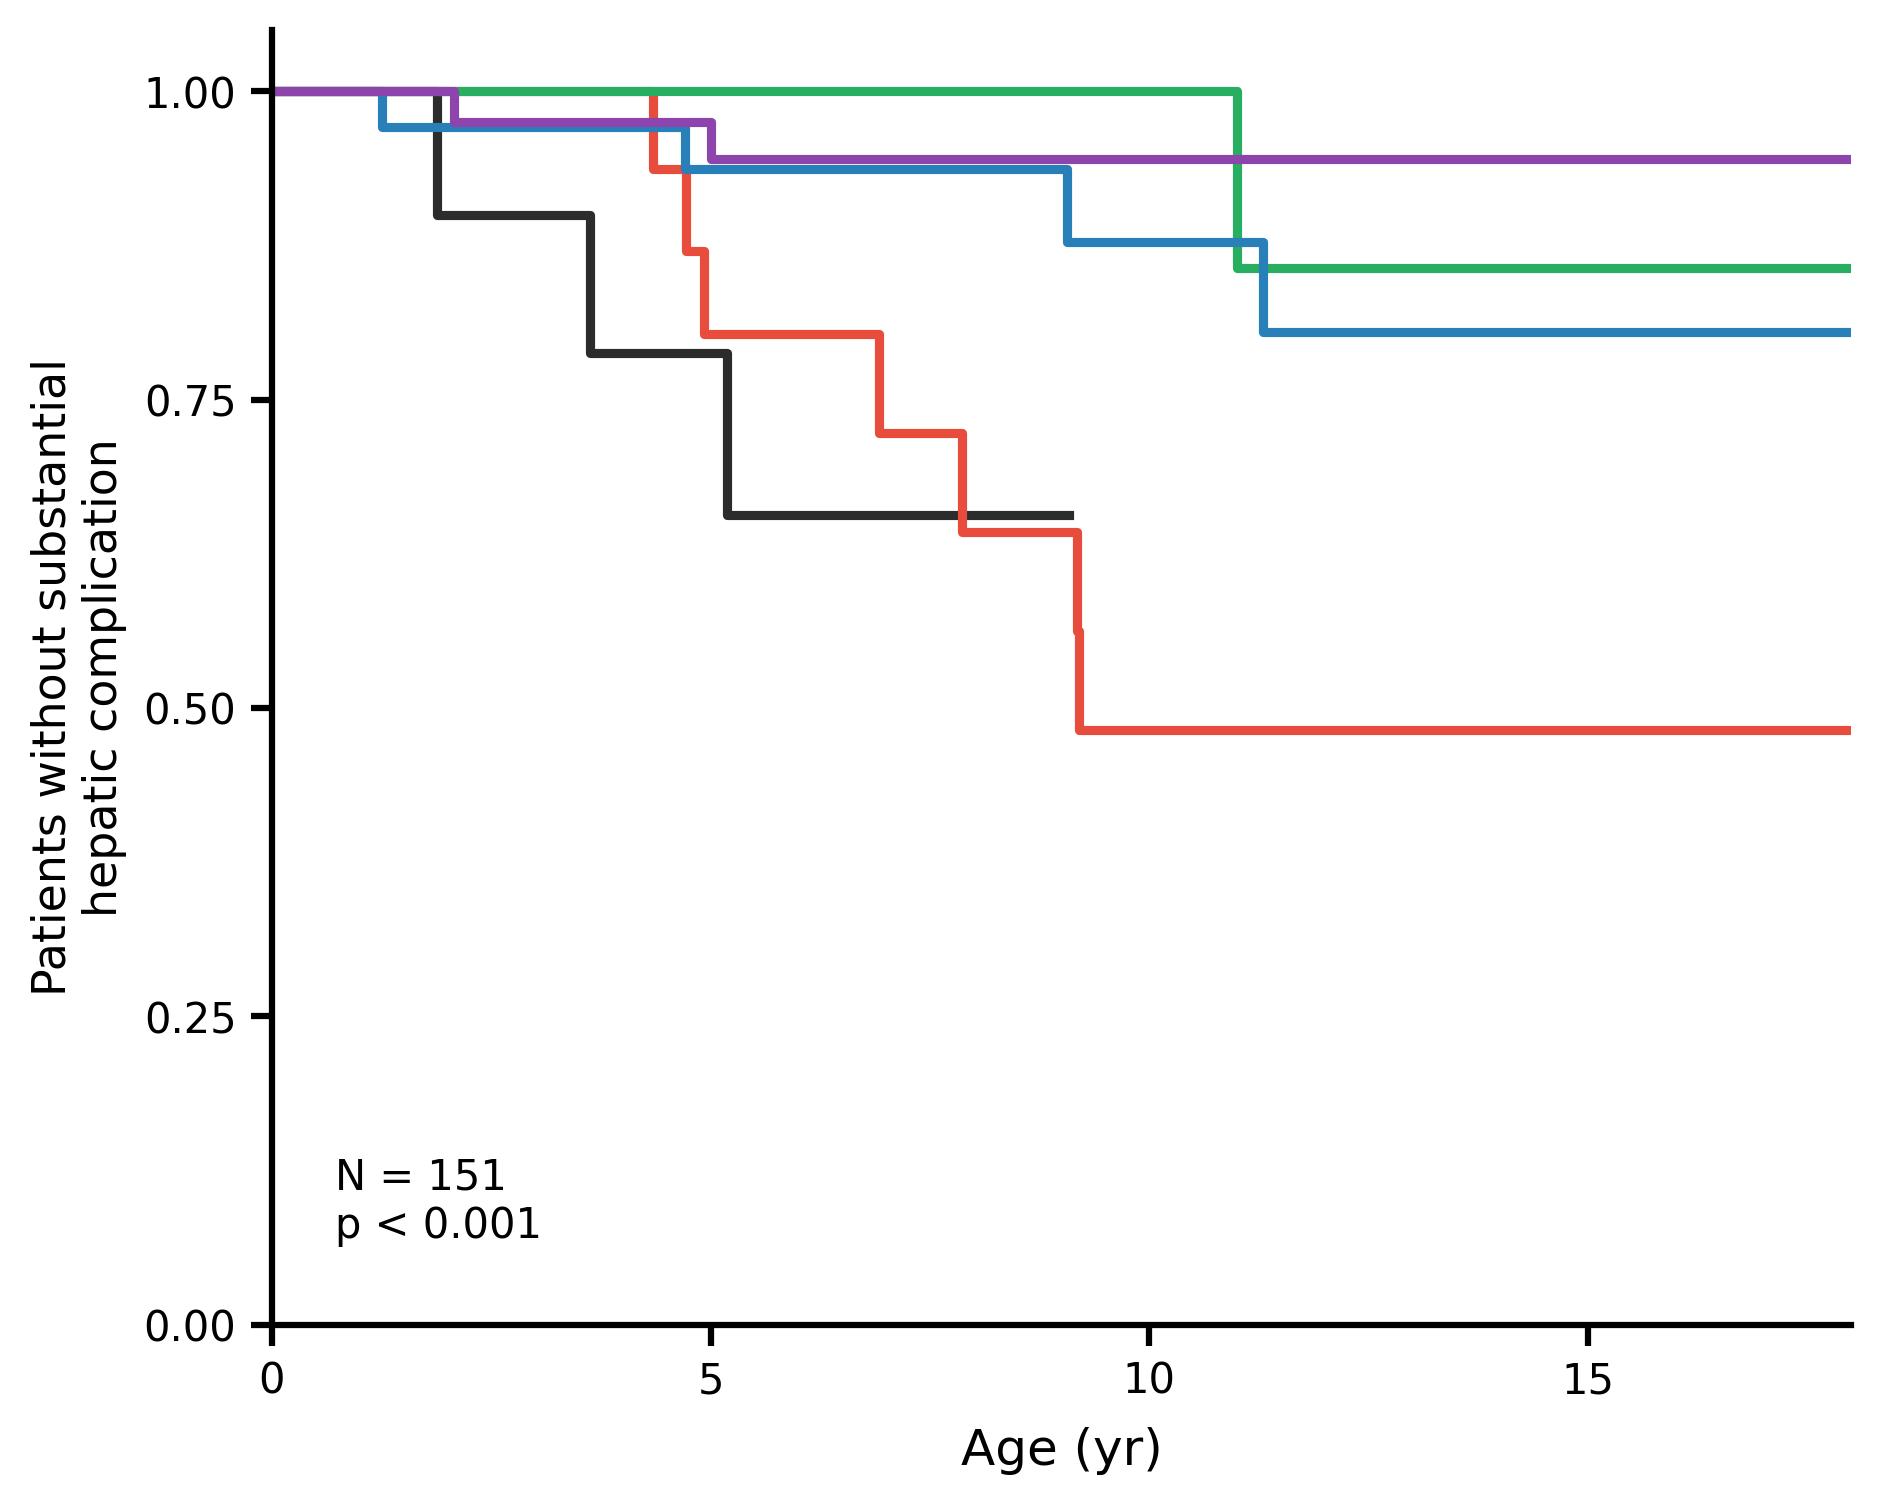

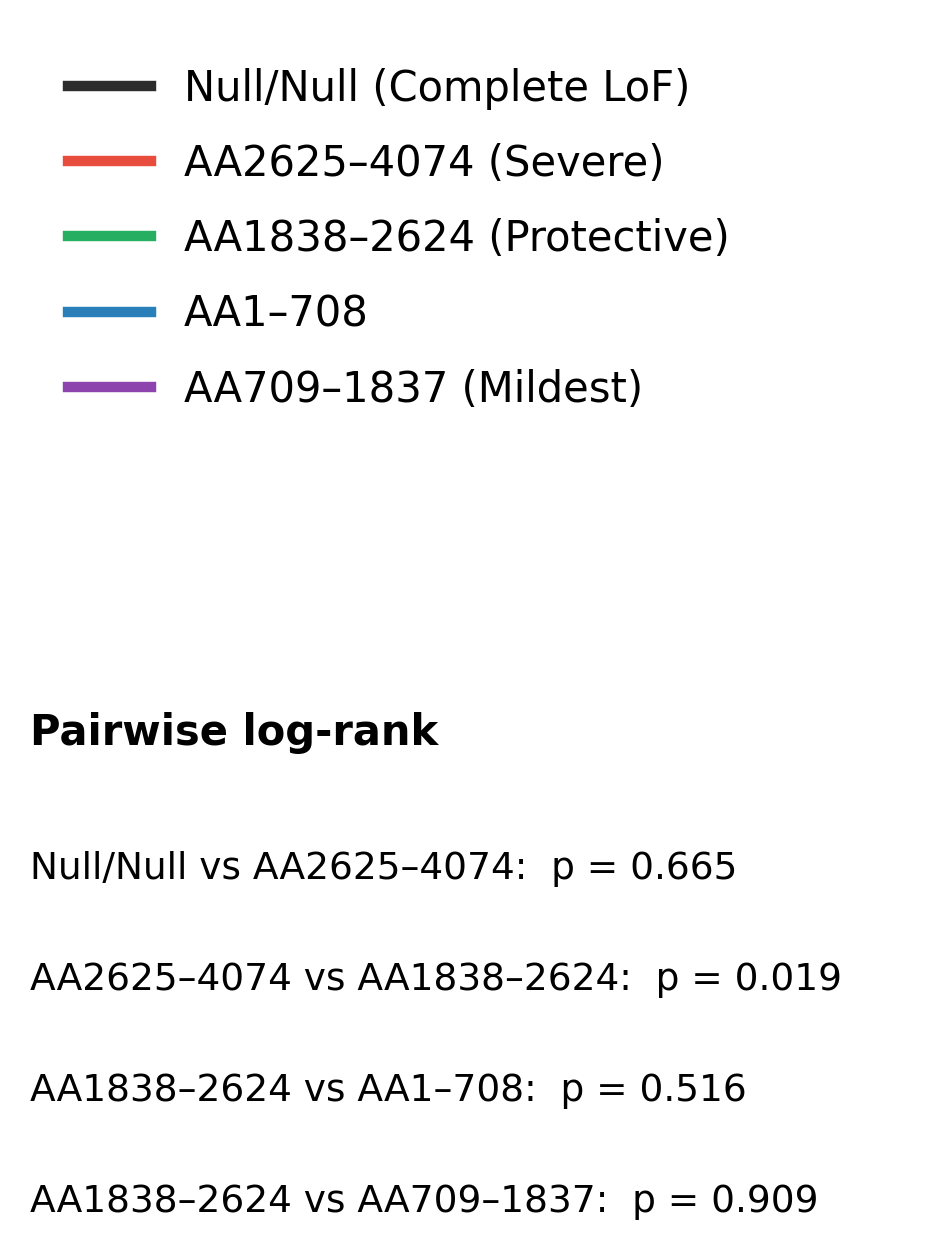

Saved: km_hepatic_with_null.png
Saved: km_hepatic_with_null_legend.png


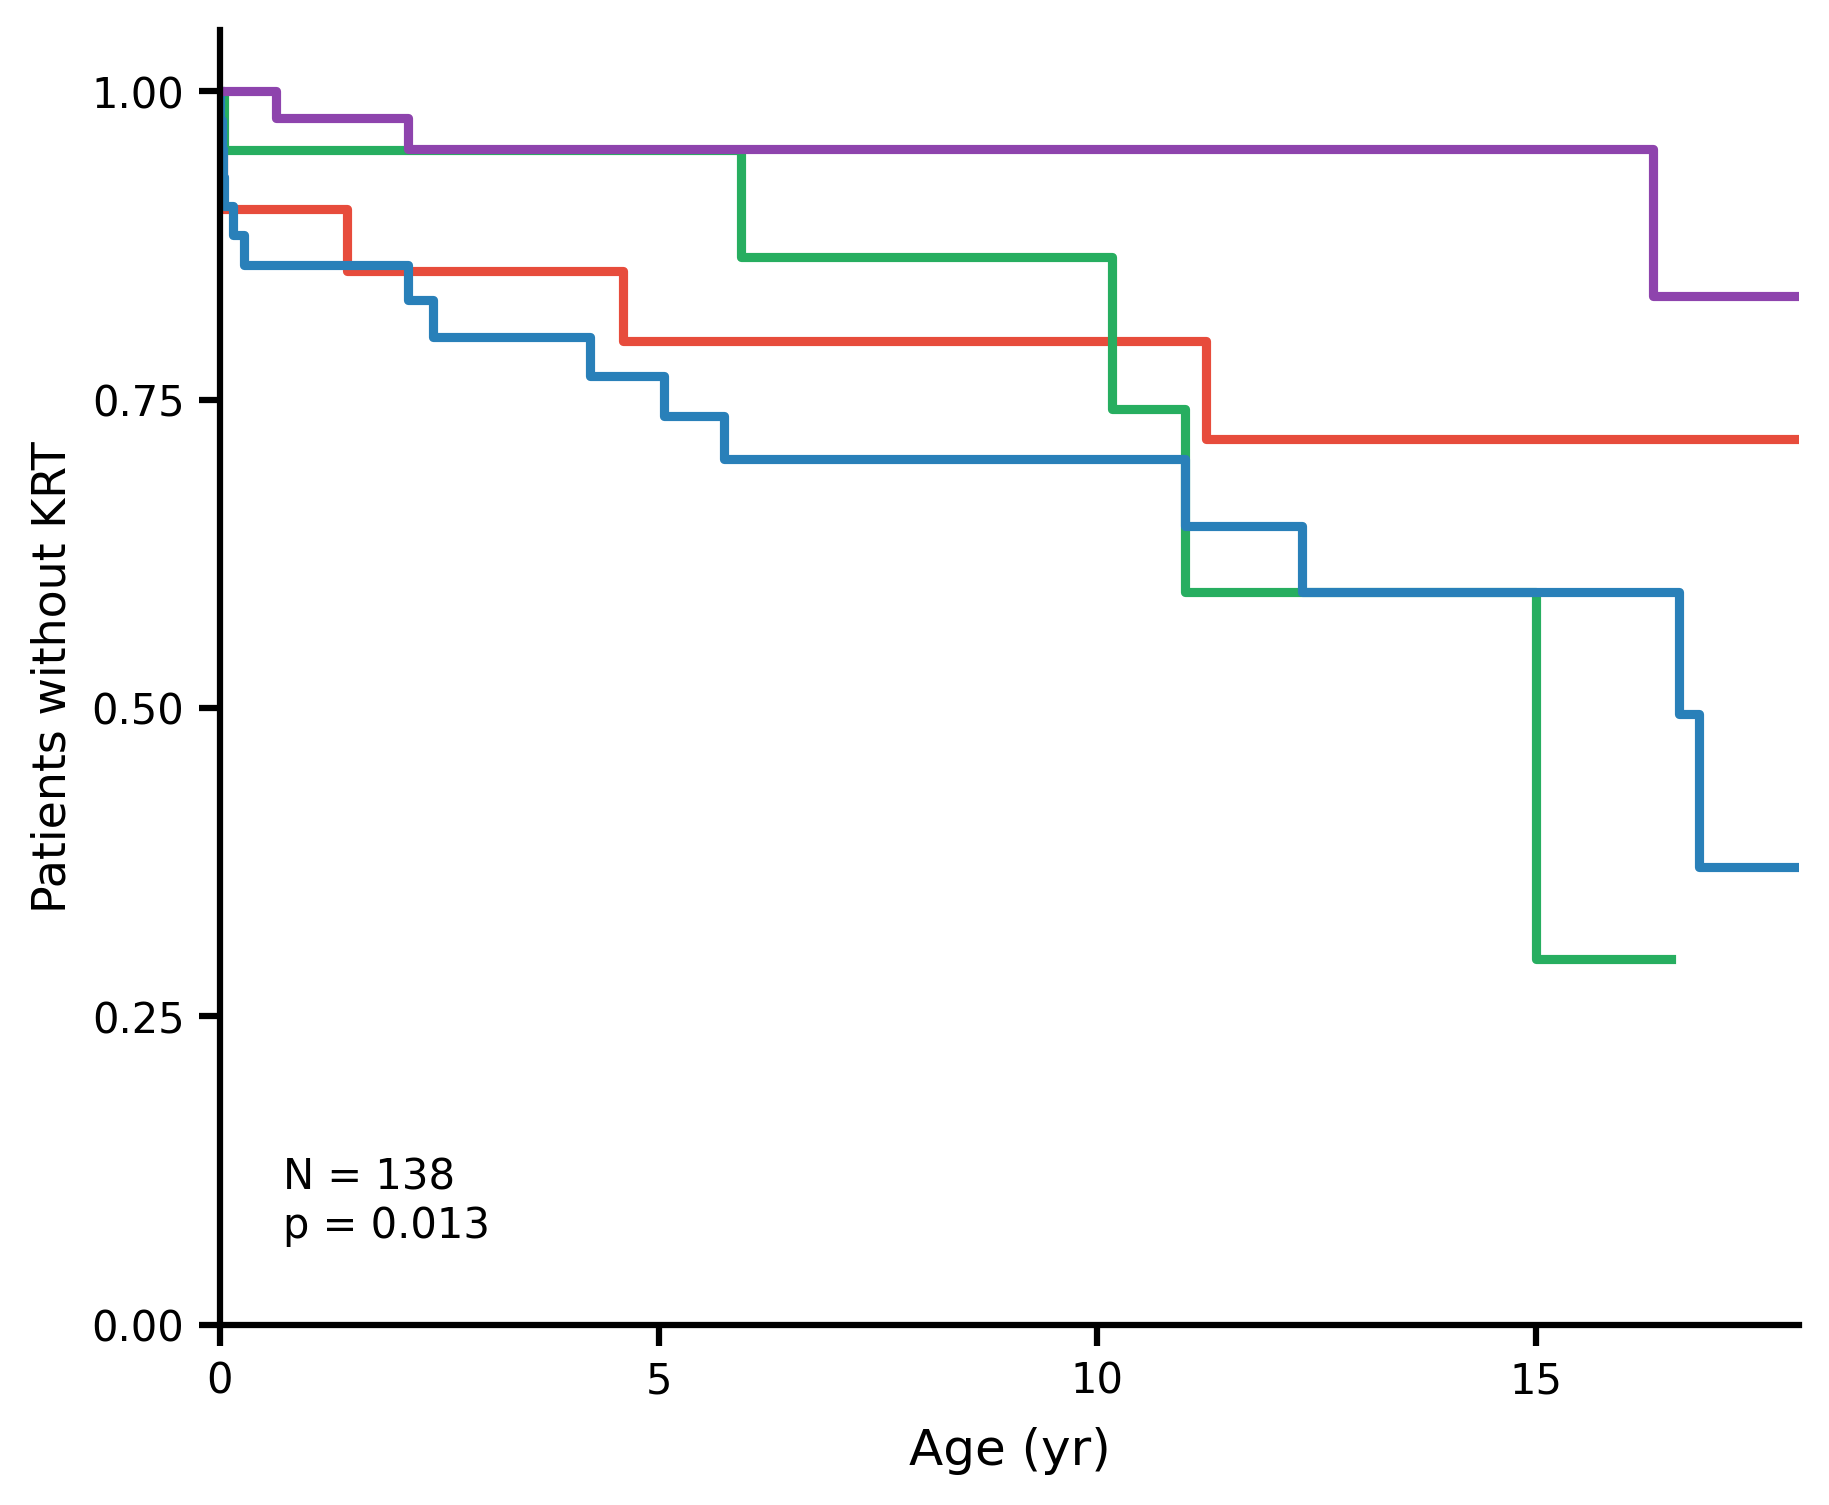

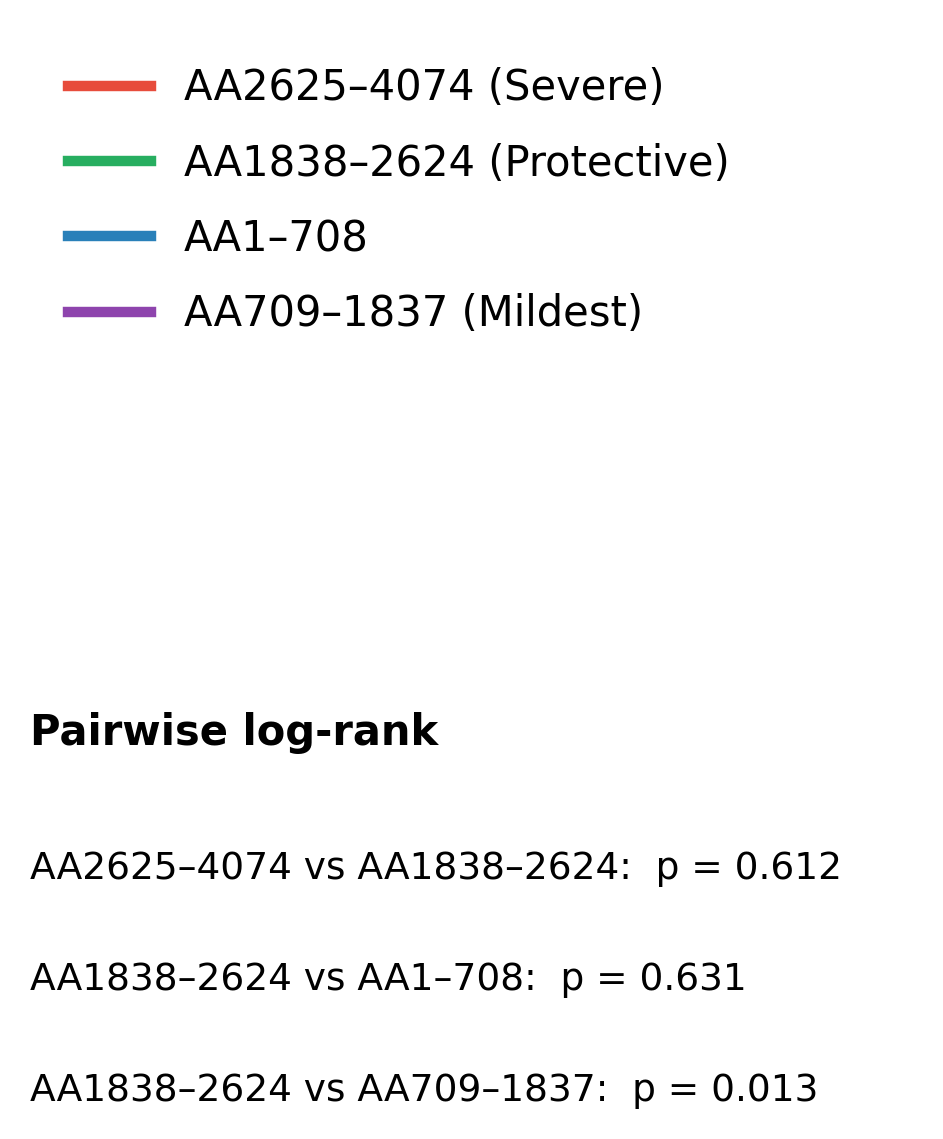

Saved: km_krt_without_null.png
Saved: km_krt_without_null_legend.png


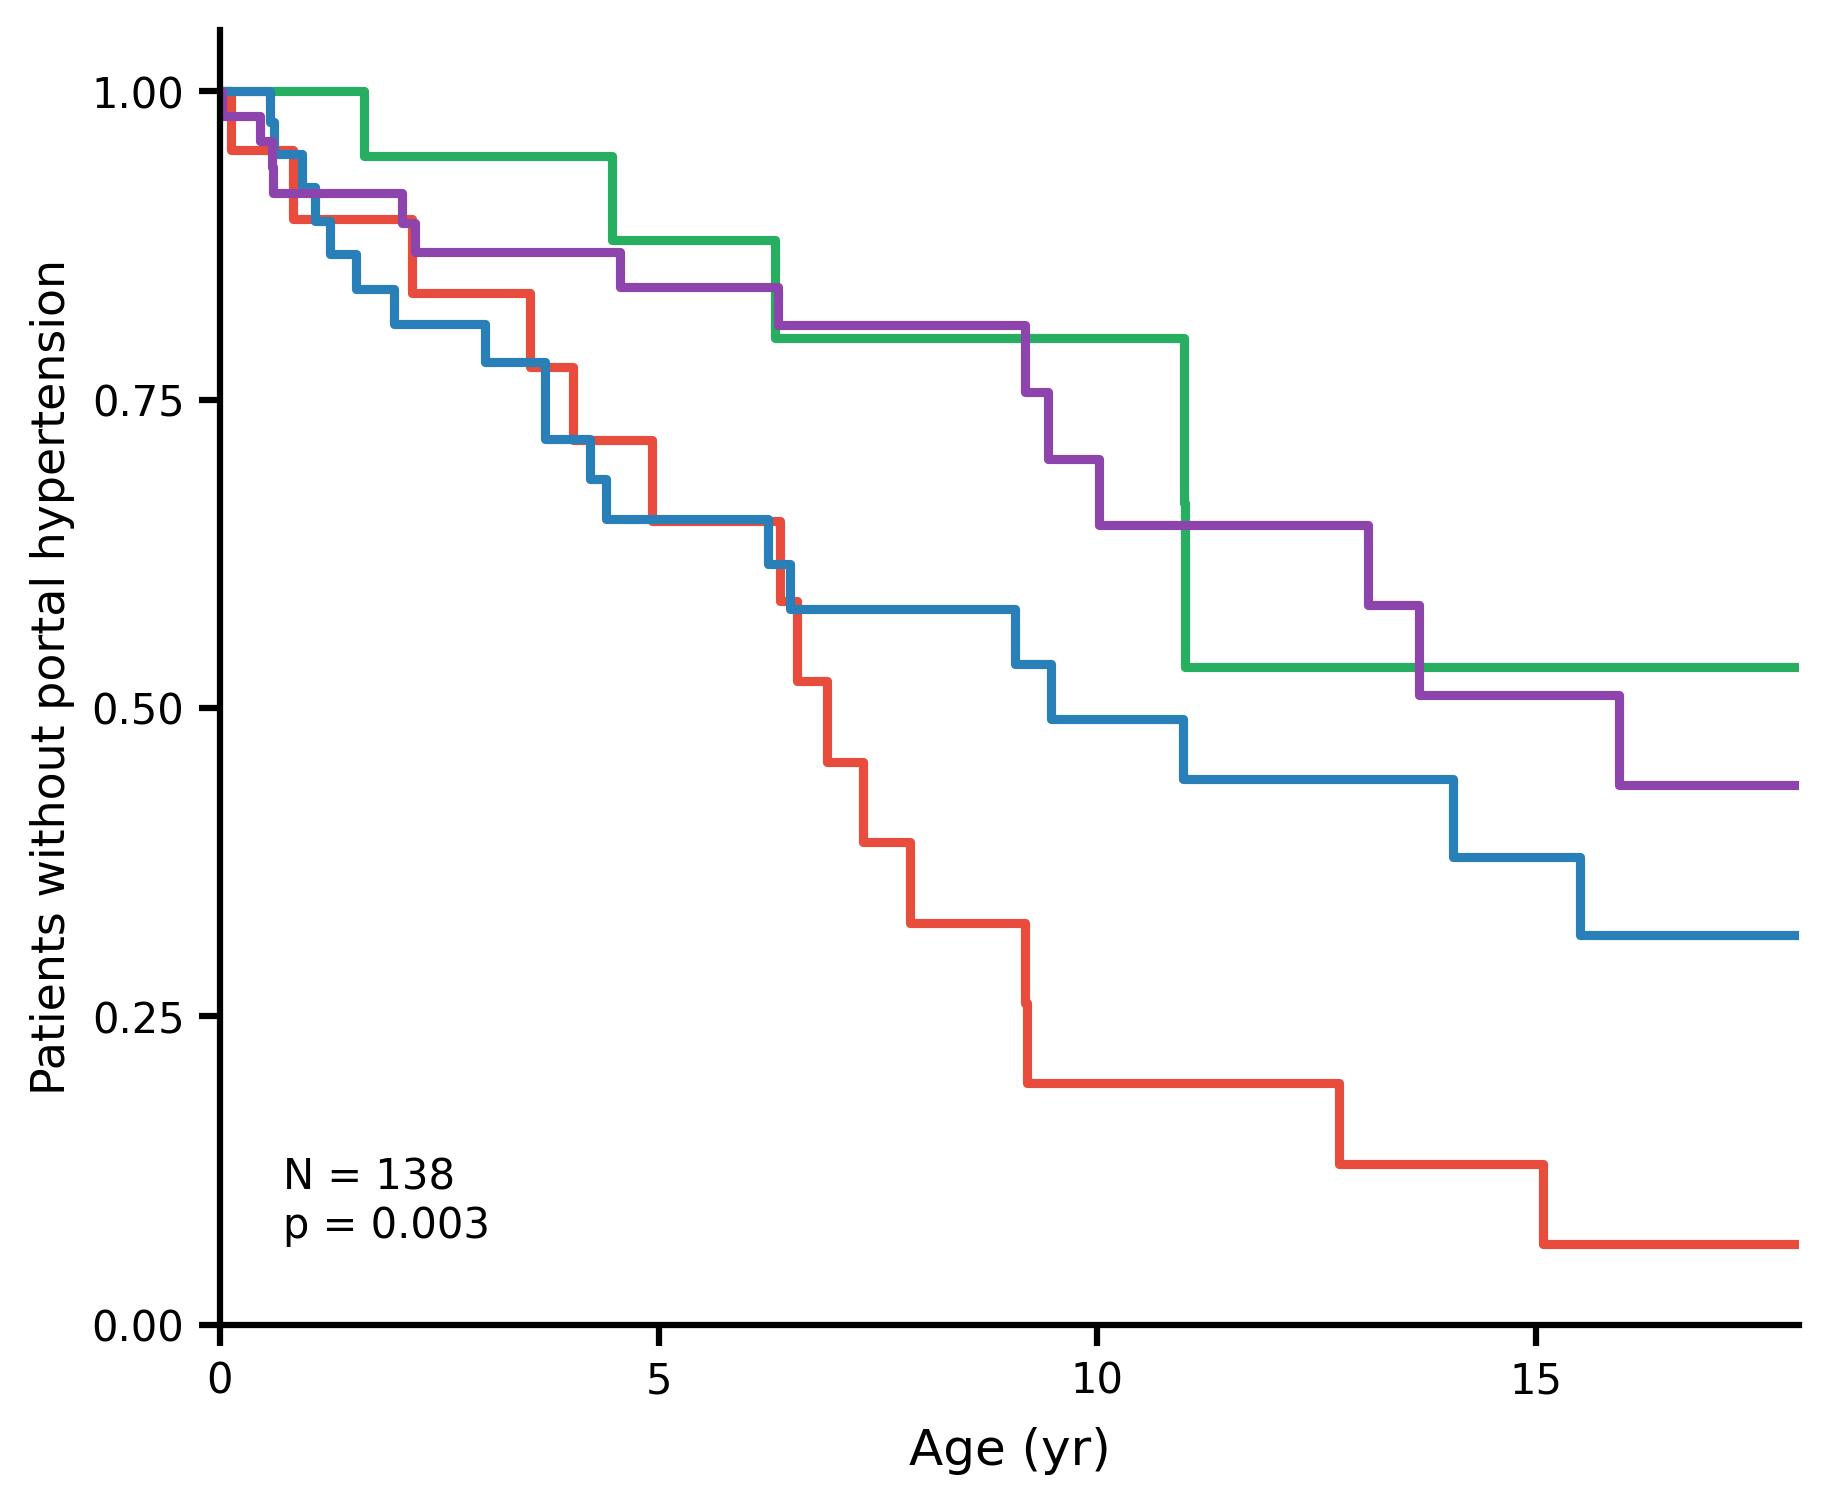

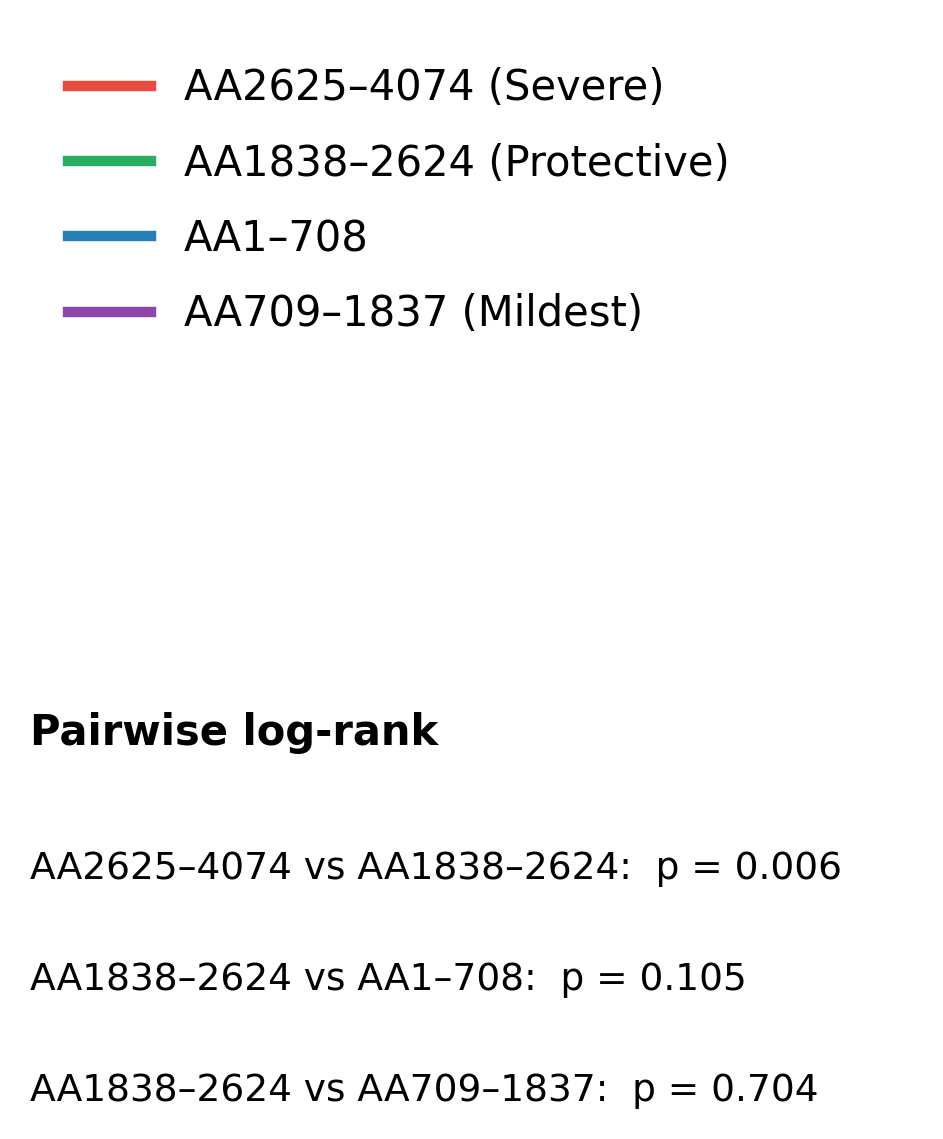

Saved: km_portal_htn_without_null.png
Saved: km_portal_htn_without_null_legend.png


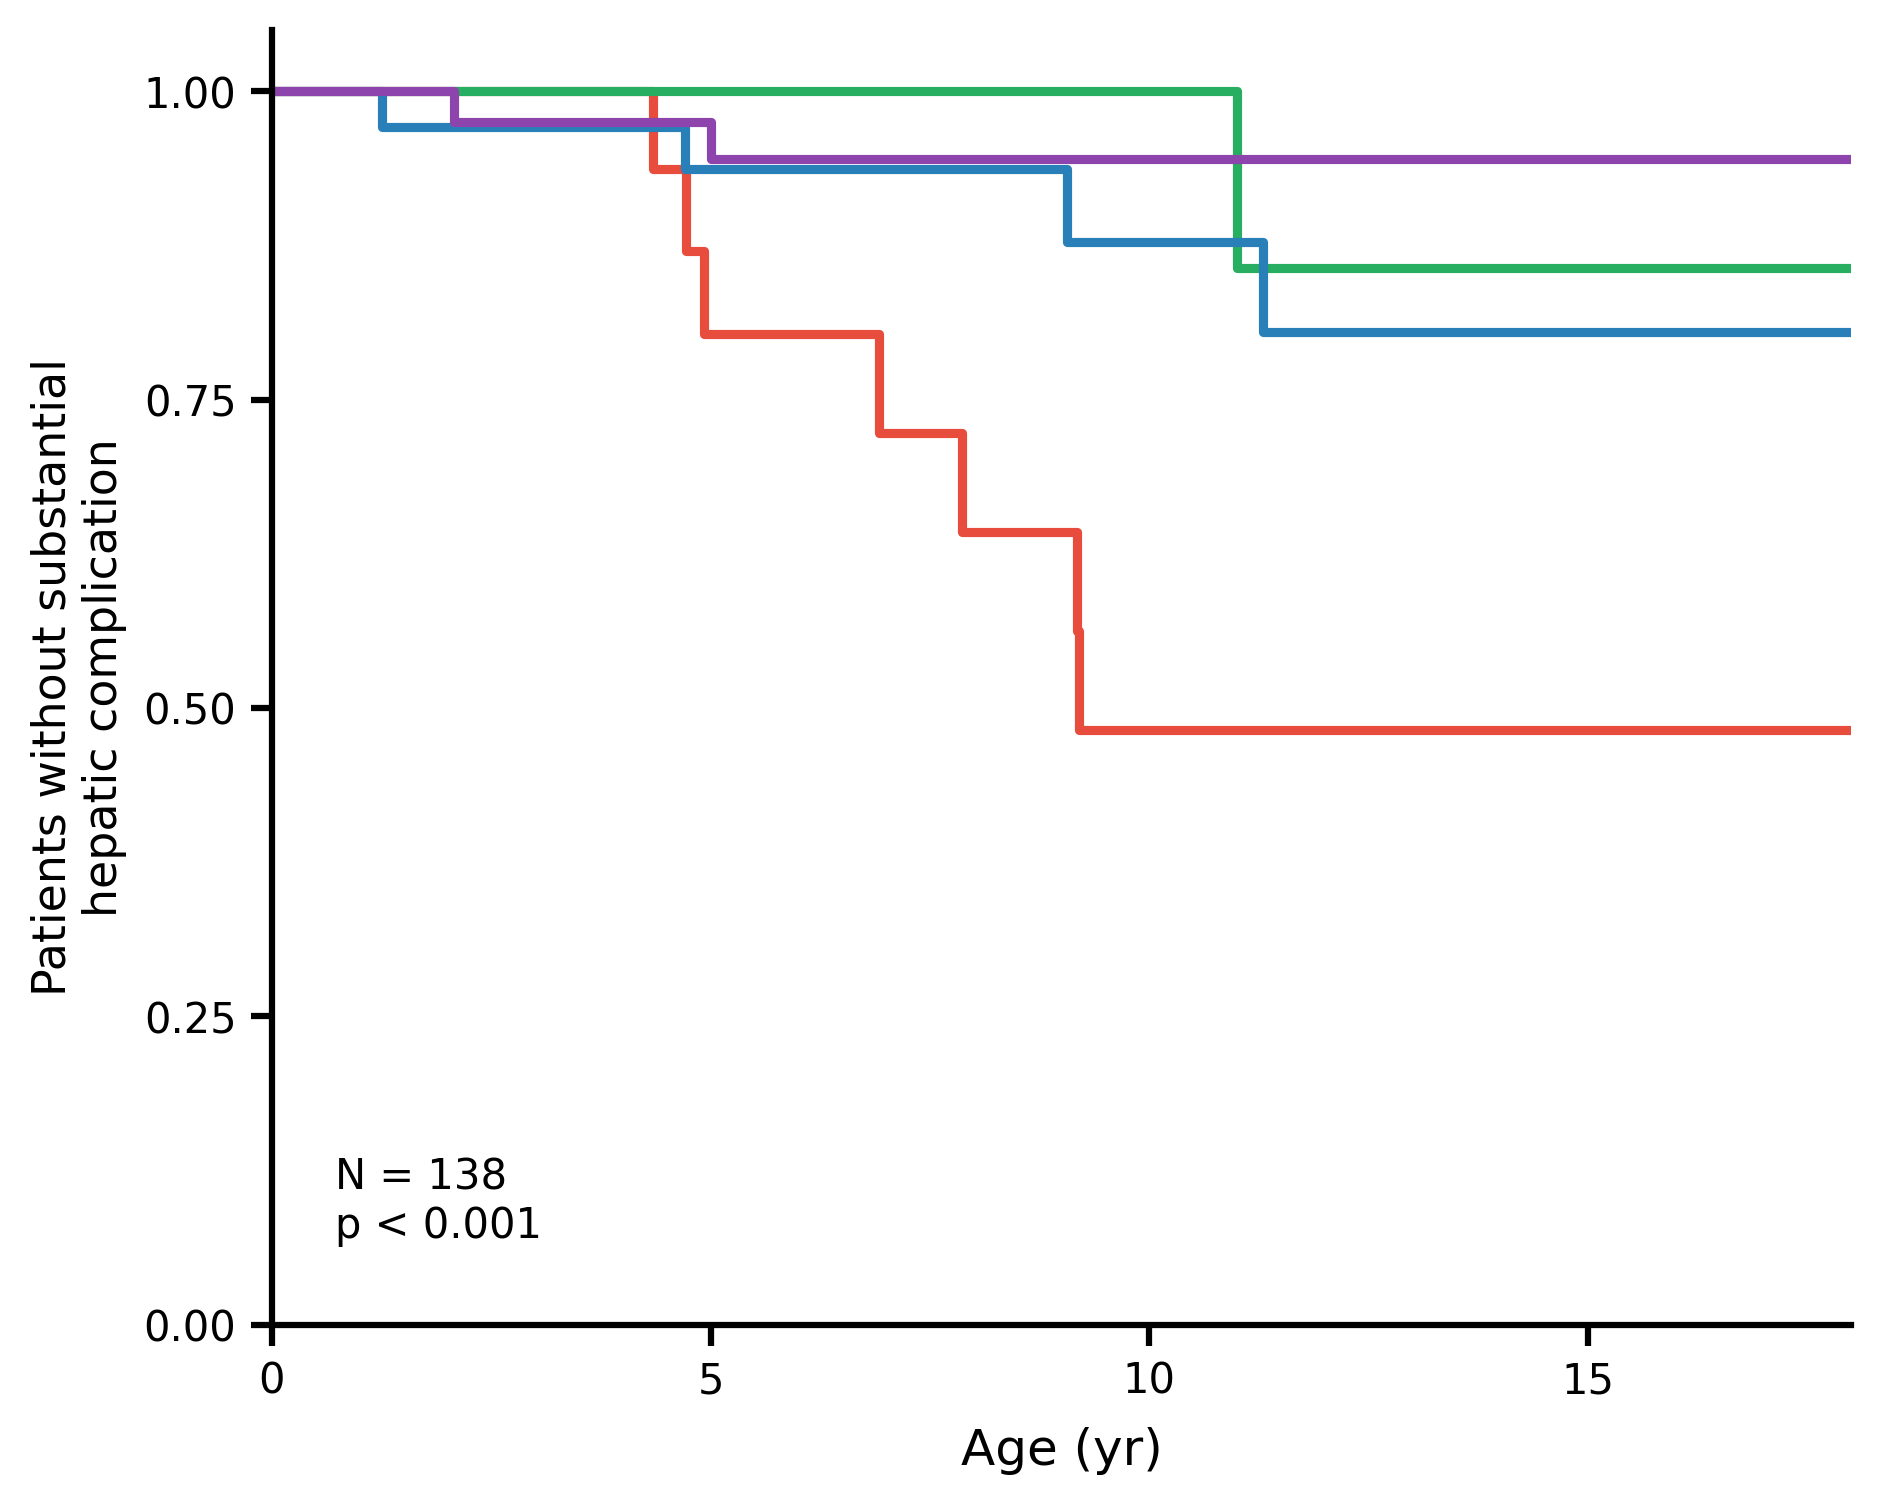

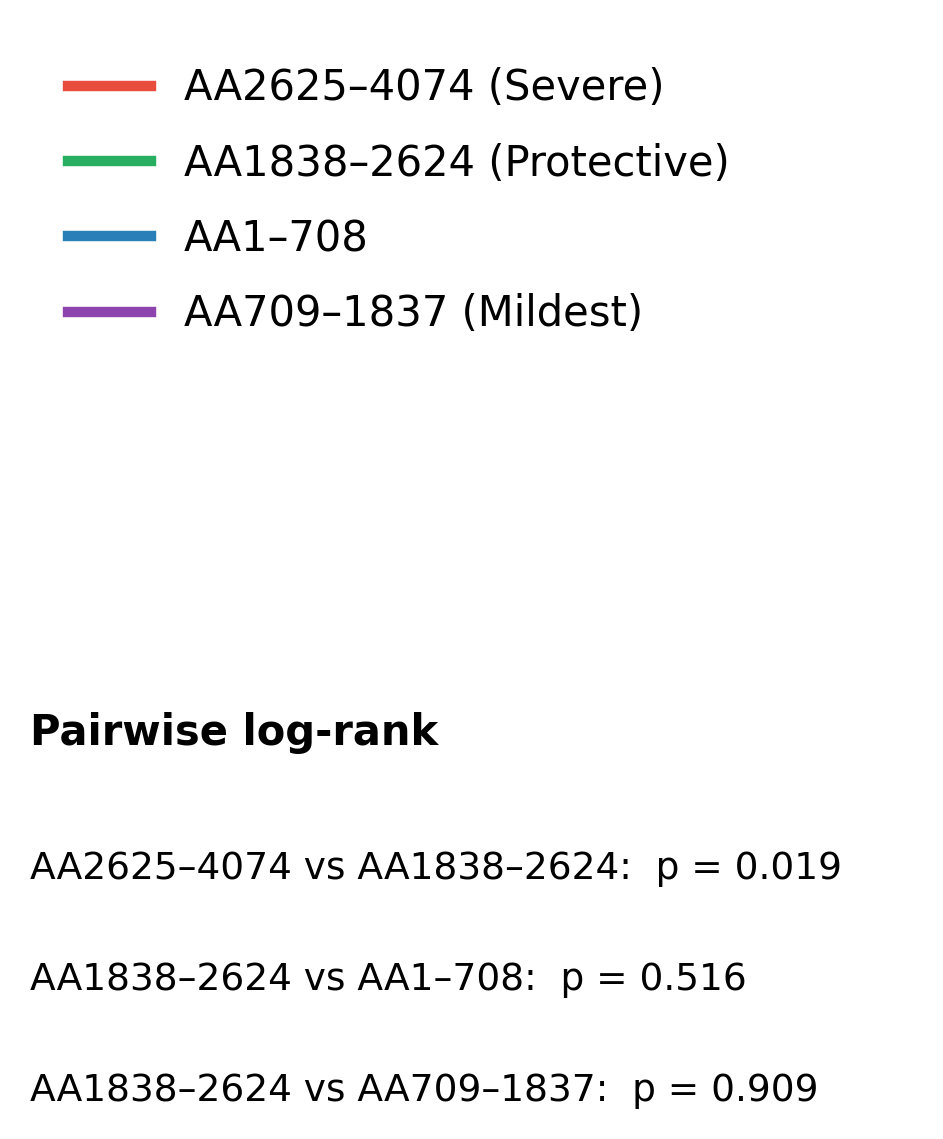

Saved: km_hepatic_without_null.png
Saved: km_hepatic_without_null_legend.png


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test

# ── Style ──────────────────────────────────────────────────────────────────

plt.rcParams.update({
    'font.family':        'DejaVu Sans',
    'font.size':          11,
    'axes.linewidth':     1.5,
    'axes.spines.top':    False,
    'axes.spines.right':  False,
    'xtick.major.width':  1.5,
    'ytick.major.width':  1.5,
    'xtick.major.size':   5,
    'ytick.major.size':   5,
    'legend.frameon':     False,
    'figure.dpi':         300,
    'figure.facecolor':   'none',
    'axes.facecolor':     'none',
})

# ── Helpers ────────────────────────────────────────────────────────────────

def prepare_survival(df, event_col, age_col, followup_col='followup_age'):
    duration = np.where(df[event_col] == 1, df[age_col], df[followup_col])
    duration = np.where((duration <= 0) & (df[event_col].values == 0),
                        np.nan, duration)
    duration = np.where(duration <= 0, 0.001, duration)
    mask     = ~np.isnan(duration)
    return duration[mask].astype(float), df[event_col].values[mask].astype(int)

def fmt_p(p):
    if p < 0.001: return 'p < 0.001'
    return f'p = {p:.3f}'

# ── Versions ───────────────────────────────────────────────────────────────

versions = {
    'with_null': {
        'ladder': ['Null_Null', 'AA2625_4074', 'AA1838_2624', 'AA1_708', 'AA709_1837'],
        'labels': ['Null/Null (Complete LoF)', 'AA2625–4074 (Severe)',
                   'AA1838–2624 (Protective)', 'AA1–708', 'AA709–1837 (Mildest)'],
        'colors': ['#2c2c2c', '#e74c3c', '#27ae60', '#2980b9', '#8e44ad'],
    },
    'without_null': {
        'ladder': ['AA2625_4074', 'AA1838_2624', 'AA1_708', 'AA709_1837'],
        'labels': ['AA2625–4074 (Severe)', 'AA1838–2624 (Protective)',
                   'AA1–708', 'AA709–1837 (Mildest)'],
        'colors': ['#e74c3c', '#27ae60', '#2980b9', '#8e44ad'],
    },
}

pairs_all = [
    ('Null_Null',   'AA2625_4074', 'Null/Null vs AA2625–4074'),
    ('AA2625_4074', 'AA1838_2624', 'AA2625–4074 vs AA1838–2624'),
    ('AA1838_2624', 'AA1_708',     'AA1838–2624 vs AA1–708'),
    ('AA1838_2624', 'AA709_1837',  'AA1838–2624 vs AA709–1837'),
]
pairs_no_null = [p for p in pairs_all if p[0] != 'Null_Null']

endpoints = [
    ('had_krt',        'krt_age',
     'Patients without KRT',                              'km_krt'),
    ('had_portal_htn', 'portal_htn_age',
     'Patients without portal hypertension',              'km_portal_htn'),
    ('had_hepatic',    'hepatic_age',
     'Patients without substantial\nhepatic complication','km_hepatic'),
]

# ── Plot ───────────────────────────────────────────────────────────────────

for version_name, version in versions.items():
    ladder = version['ladder']
    labels = version['labels']
    colors = version['colors']
    pairs  = pairs_all if version_name == 'with_null' else pairs_no_null

    for (event_col, age_col, ylabel, fname_base) in endpoints:

        fig, ax = plt.subplots(figsize=(6.5, 5.2))
        fig.patch.set_alpha(0)
        ax.patch.set_alpha(0)
        fig.subplots_adjust(left=0.16, right=0.97, top=0.96, bottom=0.13)

        # KM curves
        n_total = 0
        for region, label, color in zip(ladder, labels, colors):
            subset   = combined[combined['region'] == region].copy()
            n        = len(subset)
            n_total += n
            duration, event = prepare_survival(subset, event_col, age_col)
            kmf = KaplanMeierFitter()
            kmf.fit(duration, event_observed=event)
            kmf.plot_survival_function(
                ax=ax, ci_show=False, color=color,
                linewidth=2.2, label=label,
            )

        # Overall log-rank
        durations_all, events_all, groups_all = [], [], []
        for region in ladder:
            subset = combined[combined['region'] == region].copy()
            d, e   = prepare_survival(subset, event_col, age_col)
            durations_all.extend(d)
            events_all.extend(e)
            groups_all.extend([region] * len(d))
        result = multivariate_logrank_test(durations_all, groups_all, events_all)
        ax.text(0.04, 0.06,
                f'N = {n_total}\n{fmt_p(result.p_value)}',
                transform=ax.transAxes, fontsize=10,
                va='bottom', ha='left')

        # Remove lifelines auto-legend
        leg = ax.get_legend()
        if leg: leg.remove()

        # Axes
        ax.set_xlim(0, 18)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel('Age (yr)', fontsize=12, labelpad=6)
        ax.set_ylabel(ylabel, fontsize=11)
        ax.set_xticks([0, 5, 10, 15])
        ax.set_yticks([0.00, 0.25, 0.50, 0.75, 1.00])
        ax.yaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, _: f'{x:.2f}'))
        ax.tick_params(axis='both', labelsize=10)

        # ── Separate legend figure ─────────────────────────────────────────
        fig_leg, ax_leg = plt.subplots(figsize=(3.8, 3.2))
        fig_leg.patch.set_alpha(0)
        ax_leg.patch.set_alpha(0)
        ax_leg.axis('off')

        # Legend entries
        legend_handles = [plt.Line2D([0], [0], color=c, linewidth=2.5)
                          for c in colors]
        legend = ax_leg.legend(
            legend_handles, labels,
            loc='upper left', fontsize=10,
            frameon=False, handlelength=2.0,
            labelspacing=0.8,
        )

        # Pairwise p-values below legend
        y_start = 0.02
        ax_leg.text(0.0, y_start, 'Pairwise log-rank',
                    transform=ax_leg.transAxes,
                    fontsize=10, fontweight='bold', va='bottom')
        y_start -= 0.18
        for r1, r2, plabel in pairs:
            s1 = combined[combined['region'] == r1]
            s2 = combined[combined['region'] == r2]
            d1, e1 = prepare_survival(s1, event_col, age_col)
            d2, e2 = prepare_survival(s2, event_col, age_col)
            lr = logrank_test(d1, d2, e1, e2)
            ax_leg.text(0.0, y_start,
                        f'{plabel}:  {fmt_p(lr.p_value)}',
                        transform=ax_leg.transAxes,
                        fontsize=9, va='bottom')
            y_start -= 0.15

        # Save both
        fname_plot   = f'{fname_base}_{version_name}.png'
        fname_legend = f'{fname_base}_{version_name}_legend.png'
        fig.savefig(fname_plot,   dpi=300, bbox_inches='tight',
                    transparent=True)
        fig_leg.savefig(fname_legend, dpi=300, bbox_inches='tight',
                        transparent=True)
        plt.show()
        print(f'Saved: {fname_plot}')
        print(f'Saved: {fname_legend}')

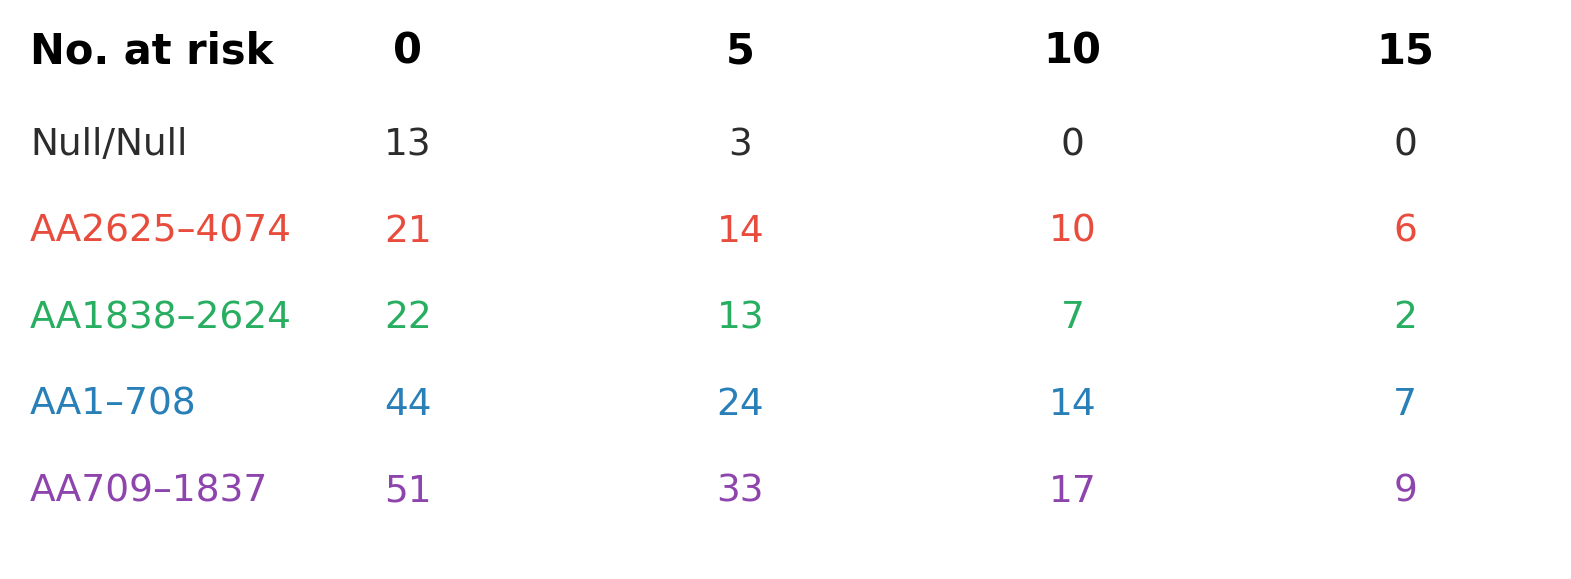

Saved: km_krt_with_null_atrisk.png


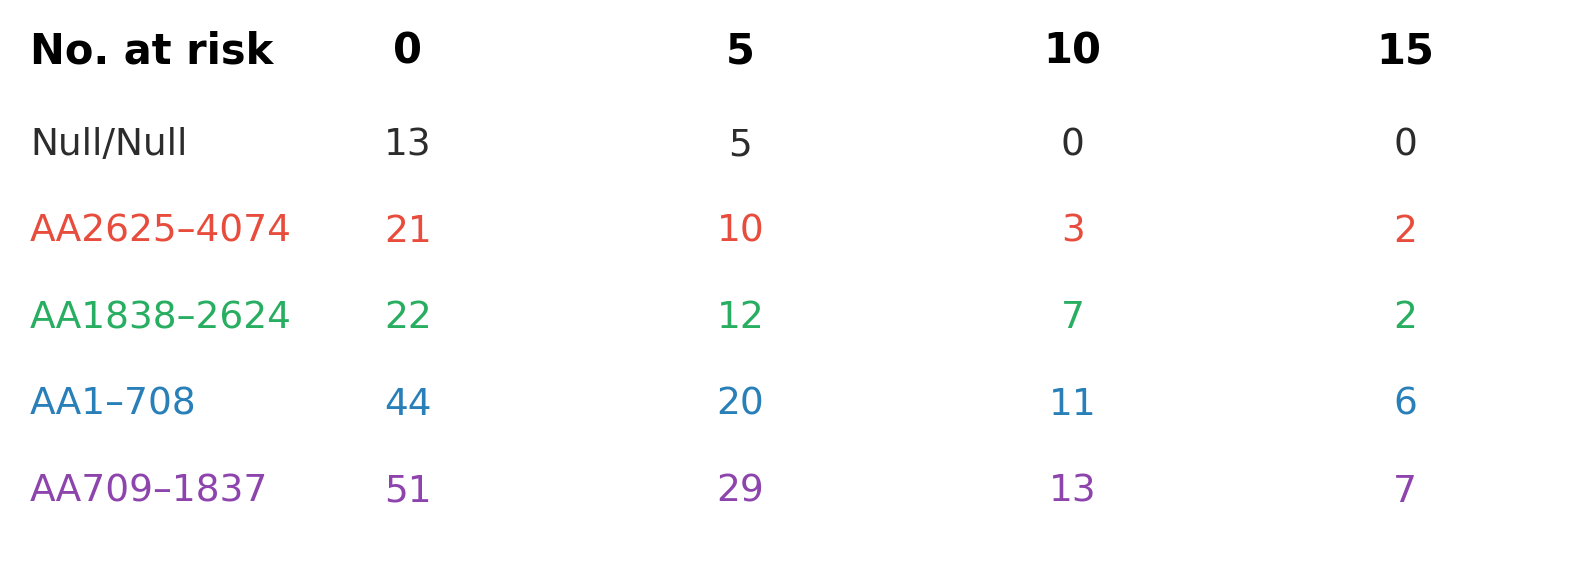

Saved: km_portal_htn_with_null_atrisk.png


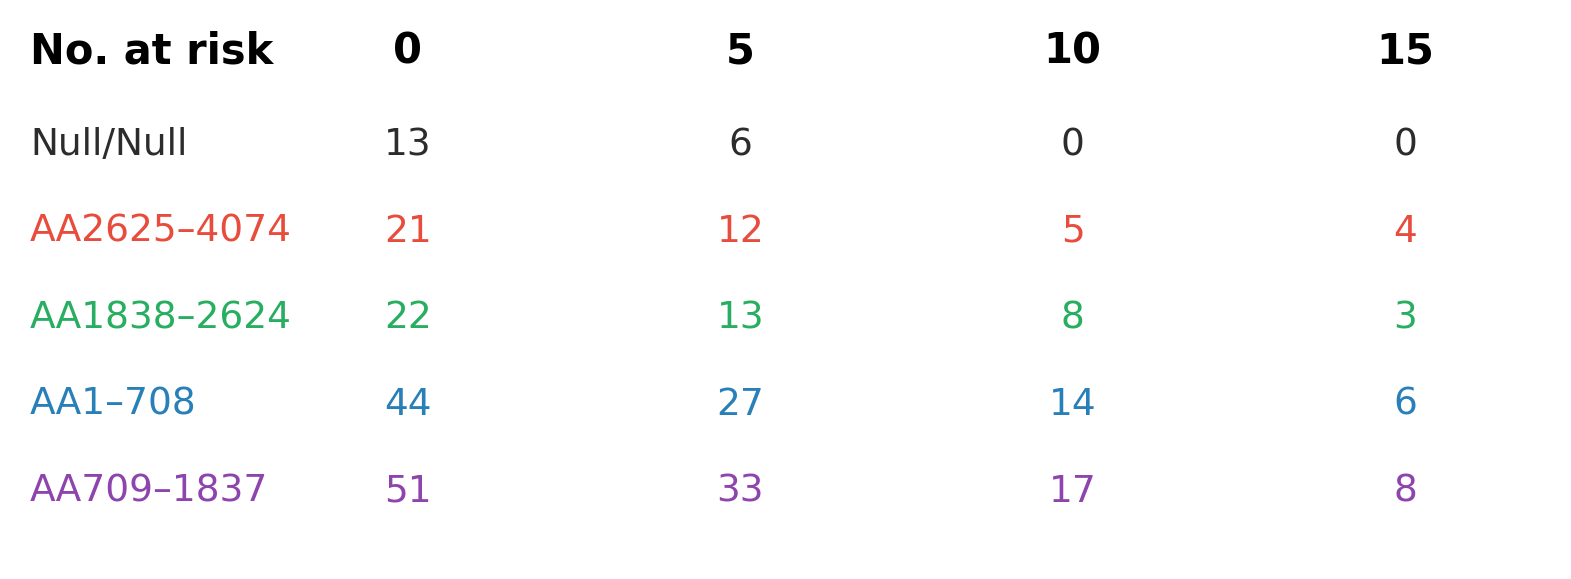

Saved: km_hepatic_with_null_atrisk.png


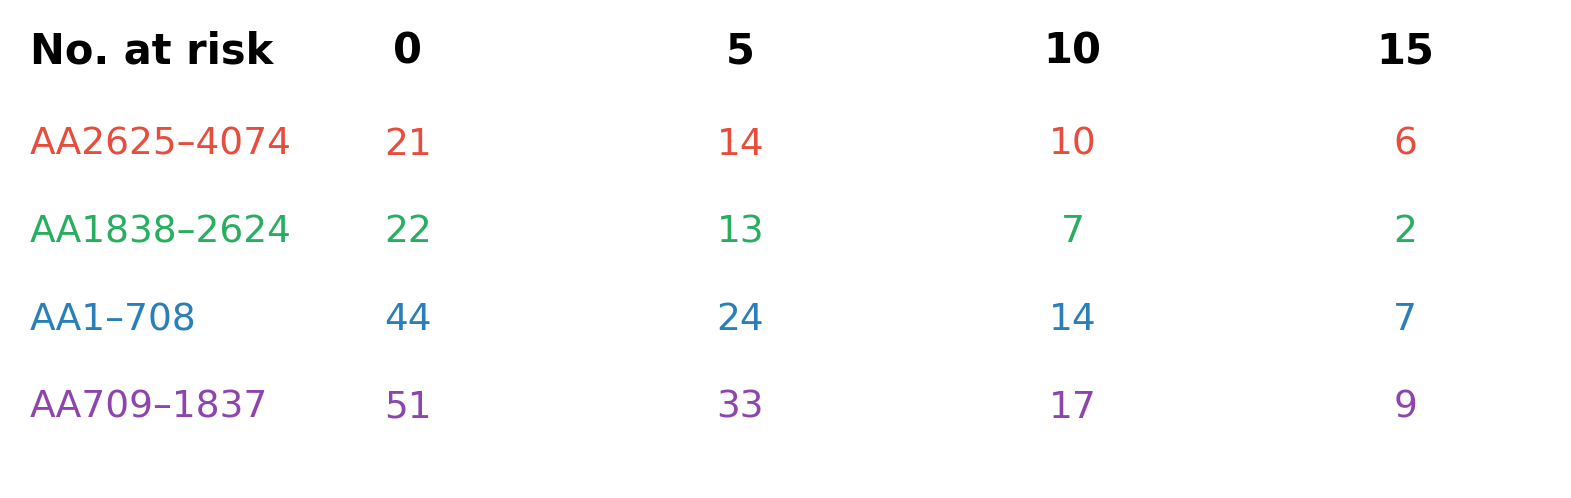

Saved: km_krt_without_null_atrisk.png


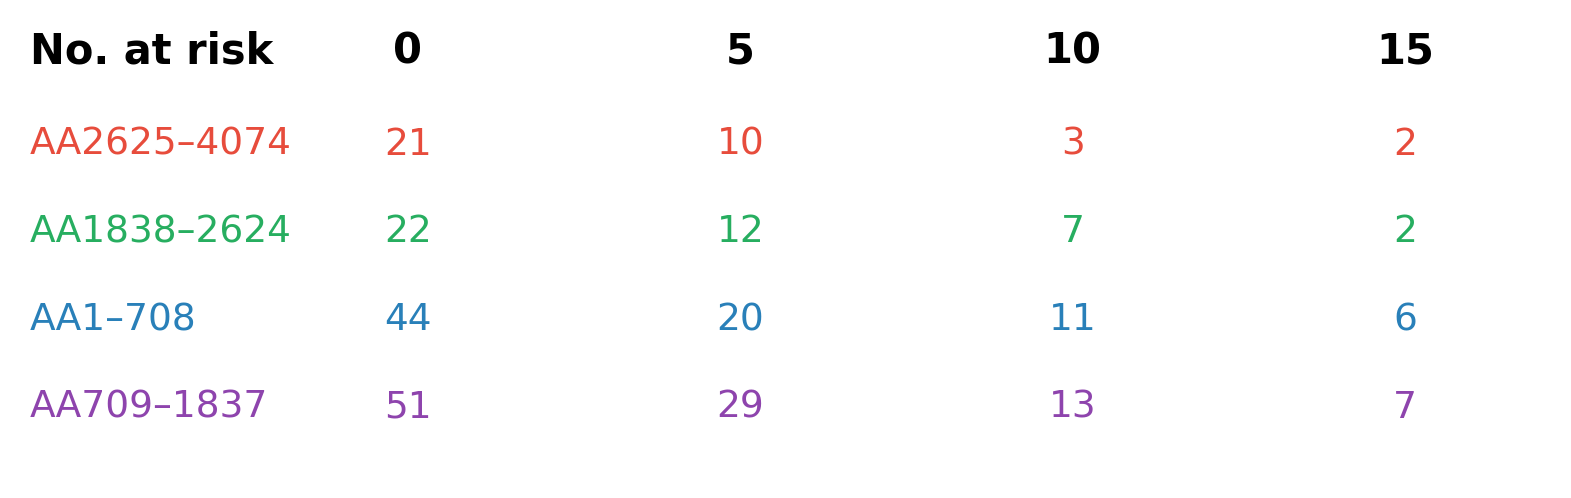

Saved: km_portal_htn_without_null_atrisk.png


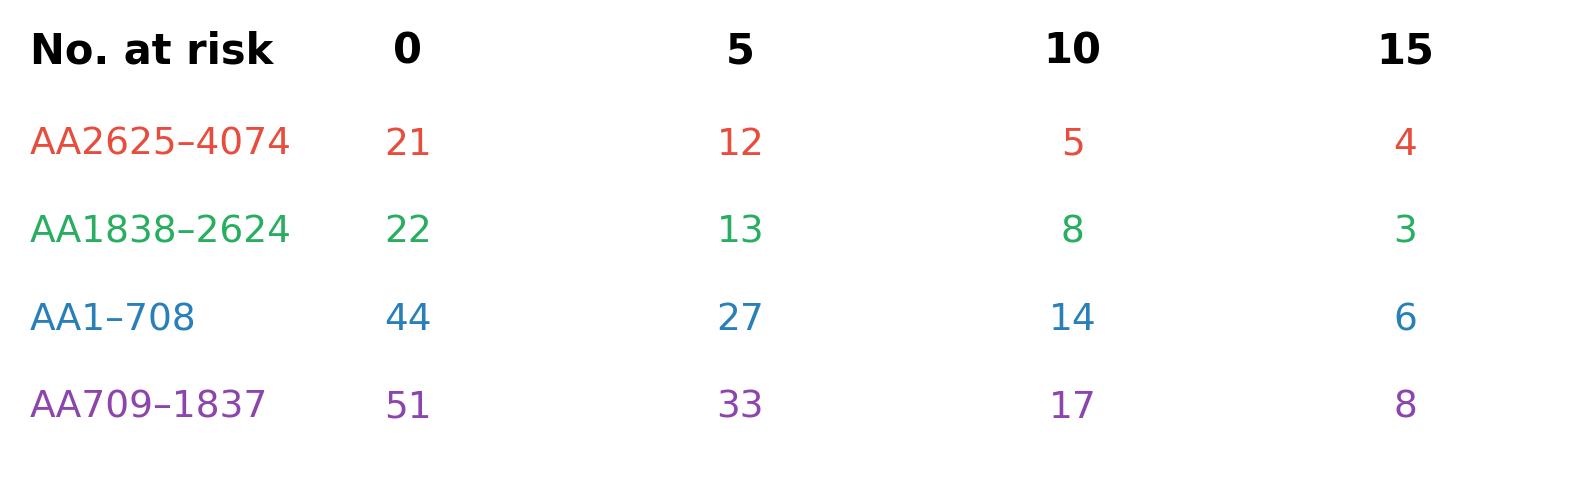

Saved: km_hepatic_without_null_atrisk.png


In [ ]:
# ── At-risk tables — corrected count method ───────────────────────────────

for version_name, version in versions.items():
    ladder = version['ladder']
    labels = version['labels']
    colors = version['colors']

    for (event_col, age_col, ylabel, fname_base) in endpoints:

        timepoints = [0, 5, 10, 15]
        n_rows     = len(ladder)

        fig, ax = plt.subplots(figsize=(6.5, n_rows * 0.35 + 0.5))
        fig.patch.set_alpha(0)
        ax.patch.set_alpha(0)
        ax.axis('off')

        # Header
        ax.text(0.0, 1.0, 'No. at risk',
                transform=ax.transAxes,
                fontsize=10, fontweight='bold', va='top', ha='left')
        for j, t in enumerate(timepoints):
            ax.text(0.25 + j * 0.22, 1.0, str(t),
                    transform=ax.transAxes,
                    fontsize=10, fontweight='bold', va='top', ha='center')

        row_height = 1.0 / (n_rows + 1)

        for i, (region, label, color) in enumerate(zip(ladder, labels, colors)):
            subset   = combined[combined['region'] == region].copy()
            n_total  = len(subset)
            duration, event = prepare_survival(subset, event_col, age_col)

            kmf = KaplanMeierFitter()
            kmf.fit(duration, event_observed=event)

            row_y = 1.0 - (i + 1) * row_height - 0.02
            short = label.split('(')[0].strip()
            ax.text(0.0, row_y, short,
                    transform=ax.transAxes,
                    fontsize=9, color=color, va='top', ha='left')

            for j, t in enumerate(timepoints):
                if t == 0:
                    count = n_total
                else:
                    # number still at risk = those whose duration >= t
                    count = int(np.sum(duration >= t))
                ax.text(0.25 + j * 0.22, row_y, str(count),
                        transform=ax.transAxes,
                        fontsize=9, color=color, va='top', ha='center')

        fname = f'{fname_base}_{version_name}_atrisk.png'
        plt.savefig(fname, dpi=300, bbox_inches='tight', transparent=True)
        plt.show()
        print(f'Saved: {fname}')

# **Validation for KRT**

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 13.0 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=9b13406f95833ef448ad1eb7f645876818b250b33966c37ff30ad6021701da3d
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma
RSA summary per region:
             count   mean    std  min    25%    50%    75%    max
region                                                           
AA1838_2624   22.0  0.100  0.188  0.0  0.000  0.000  0.171  0.720
AA1_708       44.0  0.095  0.179  0.0  0.006  0.006  0.079  0.758
AA2625_4074   21.0  0.087  0.107  0.0  0.000  0.031  0.108  0.294
AA709_1837    51.0  0.207  0.179  0.0  0.040  0.209  0.257  0.639

Surface-exposed counts per region:
             sum  count   mean
regio

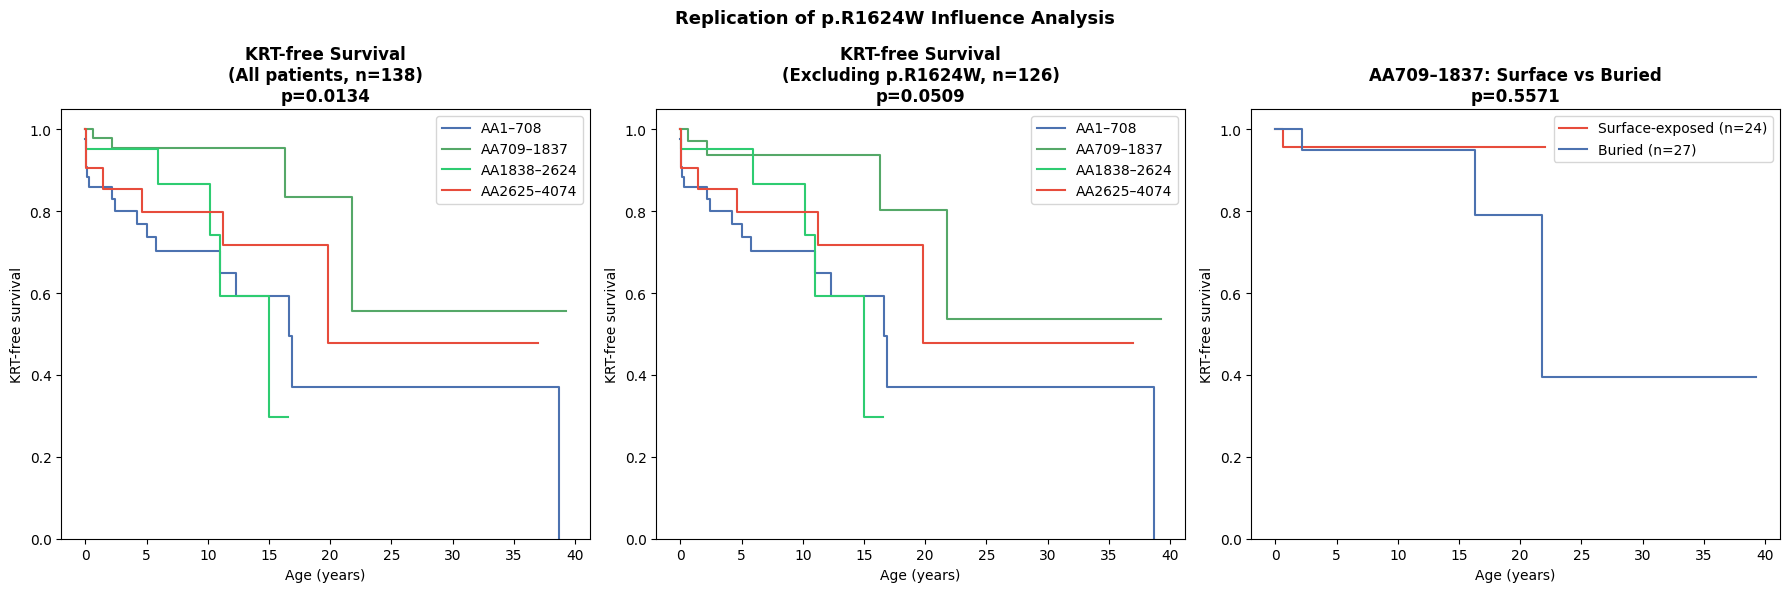


Summary:
  KM all patients p         = 0.0134
  KM excluding R1624W p     = 0.0509  (expect ~0.0587)
  P/G/R chi-square p        = 0.0024   (expect ~0.0975)
  RSA chi-square (all) p    = 0.0014
  RSA chi-square (excl) p   = 0.3026  (expect non-significant)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
!pip install lifelines
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
import scipy.stats as stats

# ── RSA threshold for surface-exposed ─────────────────────────────────────
RSA_THRESHOLD = 0.25  # standard cutoff: >0.25 = surface-exposed

# ── Flag surface exposure per patient ─────────────────────────────────────
data['rsa'] = pd.to_numeric(data['RSA'], errors='coerce')
data['surface_exposed'] = (data['rsa'] > RSA_THRESHOLD).astype(int)

print("RSA summary per region:")
print(data.groupby('region')['rsa'].describe().round(3))
print("\nSurface-exposed counts per region:")
print(data.groupby('region')['surface_exposed'].agg(['sum','count','mean']).round(3))

# ── Flag p.Arg1624Trp (p.R1624W) carriers ─────────────────────────────────
data['has_R1624W'] = data['Predicted protein change'].str.contains(
    'Arg1624Trp', na=False).astype(int)

print("\np.R1624W carrier counts per region:")
print(data.groupby('region')['has_R1624W'].sum())
print(f"\nTotal p.R1624W carriers: {data['has_R1624W'].sum()}")

# ── Flag unstructured/surface-exposed charged ref residues (P, G, R) ──────
# Extract reference amino acid from Predicted protein change
# For patients with 2 missense variants, use the one matching their region

def extract_ref_aas(protein_change, region):
    """Extract reference AAs from missense variants relevant to the region"""
    if pd.isna(protein_change):
        return []
    variants = [v.strip() for v in protein_change.split(';')]
    import re
    refs = []
    for v in variants:
        m = re.match(r'p\.([A-Z][a-z]{2})\d+[A-Z][a-z]{2}$', v)
        if m:
            refs.append(m.group(1))
    return refs

# Three-letter to one-letter AA code
aa3to1 = {
    'Ala':'A','Arg':'R','Asn':'N','Asp':'D','Cys':'C',
    'Gln':'Q','Glu':'E','Gly':'G','His':'H','Ile':'I',
    'Leu':'L','Lys':'K','Met':'M','Phe':'F','Pro':'P',
    'Ser':'S','Thr':'T','Trp':'W','Tyr':'Y','Val':'V'
}

def has_pgr_ref(protein_change, region):
    refs = extract_ref_aas(protein_change, region)
    for r in refs:
        one = aa3to1.get(r, '')
        if one in ['P', 'G', 'R']:
            return 1
    return 0

data['has_PGR_ref'] = data.apply(
    lambda row: has_pgr_ref(row['Predicted protein change'], row['region']), axis=1)

print("\nP/G/R reference residue frequencies per region:")
pgr_summary = data.groupby('region')['has_PGR_ref'].agg(['sum','count','mean']).round(3)
print(pgr_summary)

# Chi-square test across all 4 groups for P/G/R frequency
contingency_pgr = pd.crosstab(data['region'], data['has_PGR_ref'])
chi2, p_pgr, dof, expected = stats.chi2_contingency(contingency_pgr)
print(f"\nChi-square P/G/R across all regions: chi2={chi2:.3f}, p={p_pgr:.4f} (expect ~0.0975)")

# ── Surface exposure comparison across regions ─────────────────────────────
print("\n── Surface exposure chi-square (all patients) ──")
contingency_rsa = pd.crosstab(data['region'], data['surface_exposed'])
chi2_rsa, p_rsa, _, _ = stats.chi2_contingency(contingency_rsa)
print(f"chi2={chi2_rsa:.3f}, p={p_rsa:.4f}")

# Without p.R1624W
data_no_R1624W = data[data['has_R1624W'] == 0].copy()
print("\n── Surface exposure chi-square (WITHOUT p.R1624W, n={}) ──".format(len(data_no_R1624W)))
contingency_rsa_excl = pd.crosstab(data_no_R1624W['region'], data_no_R1624W['surface_exposed'])
chi2_rsa_excl, p_rsa_excl, _, _ = stats.chi2_contingency(contingency_rsa_excl)
print(f"chi2={chi2_rsa_excl:.3f}, p={p_rsa_excl:.4f} (expect non-significant)")

# ── KM: KRT-free survival WITH and WITHOUT p.R1624W ───────────────────────

def run_km_krt(df, title, ax):
    colors  = ['#4C72B0','#55A868','#2ecc71','#e74c3c']
    regions = ['AA1_708','AA709_1837','AA1838_2624','AA2625_4074']
    labels  = ['AA1–708','AA709–1837','AA1838–2624','AA2625–4074']

    # Build duration and event arrays
    # Duration = age at KRT if event, else age at last follow-up
    durations, events = [], []
    for _, row in df.iterrows():
        if row['had_krt'] == 1 and not np.isnan(row['krt_age']):
            durations.append(row['krt_age'])
            events.append(1)
        elif not np.isnan(row['followup_age']):
            durations.append(row['followup_age'])
            events.append(0)
        else:
            durations.append(np.nan)
            events.append(0)

    df = df.copy()
    df['duration'] = durations
    df['event']    = events
    df = df.dropna(subset=['duration'])

    kmfs = {}
    for region, label, color in zip(regions, labels, colors):
        subset = df[df['region'] == region]
        if len(subset) < 2:
            continue
        kmf = KaplanMeierFitter()
        kmf.fit(subset['duration'], subset['event'], label=label)
        kmf.plot_survival_function(ax=ax, color=color, ci_show=False)
        kmfs[region] = (subset['duration'].values, subset['event'].values)

    # Multivariate log-rank
    groups   = df[df['region'].isin(regions)]['region']
    dur_all  = df[df['region'].isin(regions)]['duration']
    evt_all  = df[df['region'].isin(regions)]['event']
    result   = multivariate_logrank_test(dur_all, groups, evt_all)

    ax.set_title(f"{title}\np={result.p_value:.4f}", fontweight='bold')
    ax.set_xlabel('Age (years)')
    ax.set_ylabel('KRT-free survival')
    ax.set_ylim(0, 1.05)
    return result.p_value

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Full cohort KM
p_full = run_km_krt(data, 'KRT-free Survival\n(All patients, n=138)', axes[0])

# Without p.R1624W
p_excl = run_km_krt(data_no_R1624W,
                    f'KRT-free Survival\n(Excluding p.R1624W, n={len(data_no_R1624W)})', axes[1])

# AA709-1837 only: surface-exposed breakdown
ax3 = axes[2]
aa709 = data[data['region'] == 'AA709_1837'].copy()
aa709_dur, aa709_evt = [], []
for _, row in aa709.iterrows():
    if row['had_krt'] == 1 and not np.isnan(row['krt_age']):
        aa709_dur.append(row['krt_age']); aa709_evt.append(1)
    elif not np.isnan(row['followup_age']):
        aa709_dur.append(row['followup_age']); aa709_evt.append(0)
    else:
        aa709_dur.append(np.nan); aa709_evt.append(0)
aa709['duration'] = aa709_dur
aa709['event']    = aa709_evt
aa709 = aa709.dropna(subset=['duration'])

for exposed, label, color in [(1,'Surface-exposed','#e74c3c'),(0,'Buried','#4C72B0')]:
    subset = aa709[aa709['surface_exposed'] == exposed]
    if len(subset) > 1:
        kmf = KaplanMeierFitter()
        kmf.fit(subset['duration'], subset['event'], label=f"{label} (n={len(subset)})")
        kmf.plot_survival_function(ax=ax3, color=color, ci_show=False)

if aa709['surface_exposed'].nunique() == 2:
    a = aa709[aa709['surface_exposed']==1]
    b = aa709[aa709['surface_exposed']==0]
    lr = logrank_test(a['duration'], b['duration'], a['event'], b['event'])
    ax3.set_title(f'AA709–1837: Surface vs Buried\np={lr.p_value:.4f}', fontweight='bold')
else:
    ax3.set_title('AA709–1837: Surface vs Buried', fontweight='bold')
ax3.set_xlabel('Age (years)')
ax3.set_ylabel('KRT-free survival')
ax3.set_ylim(0, 1.05)

plt.suptitle('Replication of p.R1624W Influence Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('R1624W_replication.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nSummary:")
print(f"  KM all patients p         = {p_full:.4f}")
print(f"  KM excluding R1624W p     = {p_excl:.4f}  (expect ~0.0587)")
print(f"  P/G/R chi-square p        = {p_pgr:.4f}   (expect ~0.0975)")
print(f"  RSA chi-square (all) p    = {p_rsa:.4f}")
print(f"  RSA chi-square (excl) p   = {p_rsa_excl:.4f}  (expect non-significant)")